# 03 — Exploring Returns

Descriptive look at daily returns **before** designing any feature.
Plan, formulas and hypotheses: Obsidian `Methodology/03 - Exploring Returns.md`.
Concepts: Obsidian `Technical Learning/`.

All statistics use **log returns** unless stated otherwise. Figures are saved to `reports/figures/` and copied to the Obsidian vault (`Quant_Momentum/Figures/03/`); tables to `reports/tables/`.

In [1]:
import shutil
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src import eda
from src.universe import BENCHMARK, TRADEABLES, UNIVERSE

PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
TAB_DIR = ROOT / "reports" / "tables"
VAULT_FIG_DIR = ROOT / "Quant_Momentum" / "Figures" / "03"
for d in (FIG_DIR, TAB_DIR, VAULT_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

simple = pd.read_parquet(PROC / "returns_daily.parquet")
logr = pd.read_parquet(PROC / "returns_daily_log.parquet")
T = len(logr)

CLASS_OF = {t: c for c, ts in UNIVERSE.items() for t in ts}
CLASS_OF[BENCHMARK] = "benchmark"
ORDERED = [t for ts in UNIVERSE.values() for t in ts] + [BENCHMARK]

EVENTS = {
    "2022-01-03": "2022 bear market",
    "2022-11-09": "FTX collapse",
    "2025-04-03": "Tariff shock",
    "2026-01-30": "Gold crash",
}

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def save_fig(fig, name):
    path = FIG_DIR / f"03_{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight")
    shutil.copy(path, VAULT_FIG_DIR / path.name)


def save_table(df, name):
    df.to_csv(TAB_DIR / f"03_{name}.csv")


def mark_events(ax, label=False):
    for date, text in EVENTS.items():
        ax.axvline(pd.Timestamp(date), color="black", lw=0.7, ls=":", alpha=0.6)
        if label:
            ax.text(pd.Timestamp(date), 1.0, " " + text, transform=ax.get_xaxis_transform(), rotation=90, va="top", fontsize=7, alpha=0.8)


def format_time_axis(ax):
    """Year labels + Apr/Jul/Oct quarter labels on every panel, even when panels share the x-axis."""
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    ax.xaxis.set_minor_formatter(mdates.DateFormatter("%b"))
    ax.tick_params(axis="x", which="major", labelbottom=True, labelsize=9, pad=13, length=6)
    ax.tick_params(axis="x", which="minor", labelbottom=True, labelsize=6.5, labelcolor="dimgray", length=3)
    ax.grid(True, which="minor", axis="x", alpha=0.12)
    ax.set_xlim(pd.Timestamp(f"{logr.index[0].year}-01-01"), logr.index[-1] + pd.Timedelta(days=7))


class LogLabel(mticker.LogFormatterSciNotation):
    """Plain log-axis labels ($2, $0.6, 3×) instead of 2×10⁰; matplotlib still decides which ticks get a label."""

    def __init__(self, prefix="", suffix=""):
        super().__init__()
        self.prefix, self.suffix = prefix, suffix

    def __call__(self, x, pos=None):
        return f"{self.prefix}{x:g}{self.suffix}" if super().__call__(x, pos) else ""


print(f"{T} daily returns per asset, {logr.index[0].date()} -> {logr.index[-1].date()}, {logr.shape[1]} assets")

1438 daily returns per asset, 2021-01-05 -> 2026-09-25, 21 assets


## Graph 1 — Growth of \$1 (log scale)

$W_{i,t} = \prod_{s \le t}(1 + R_{i,s})$. On a log axis equal heights are equal percentage moves.
**Looking for:** market regimes, which classes won/lost, co-movement inside classes, and any unexplained jump (data error).

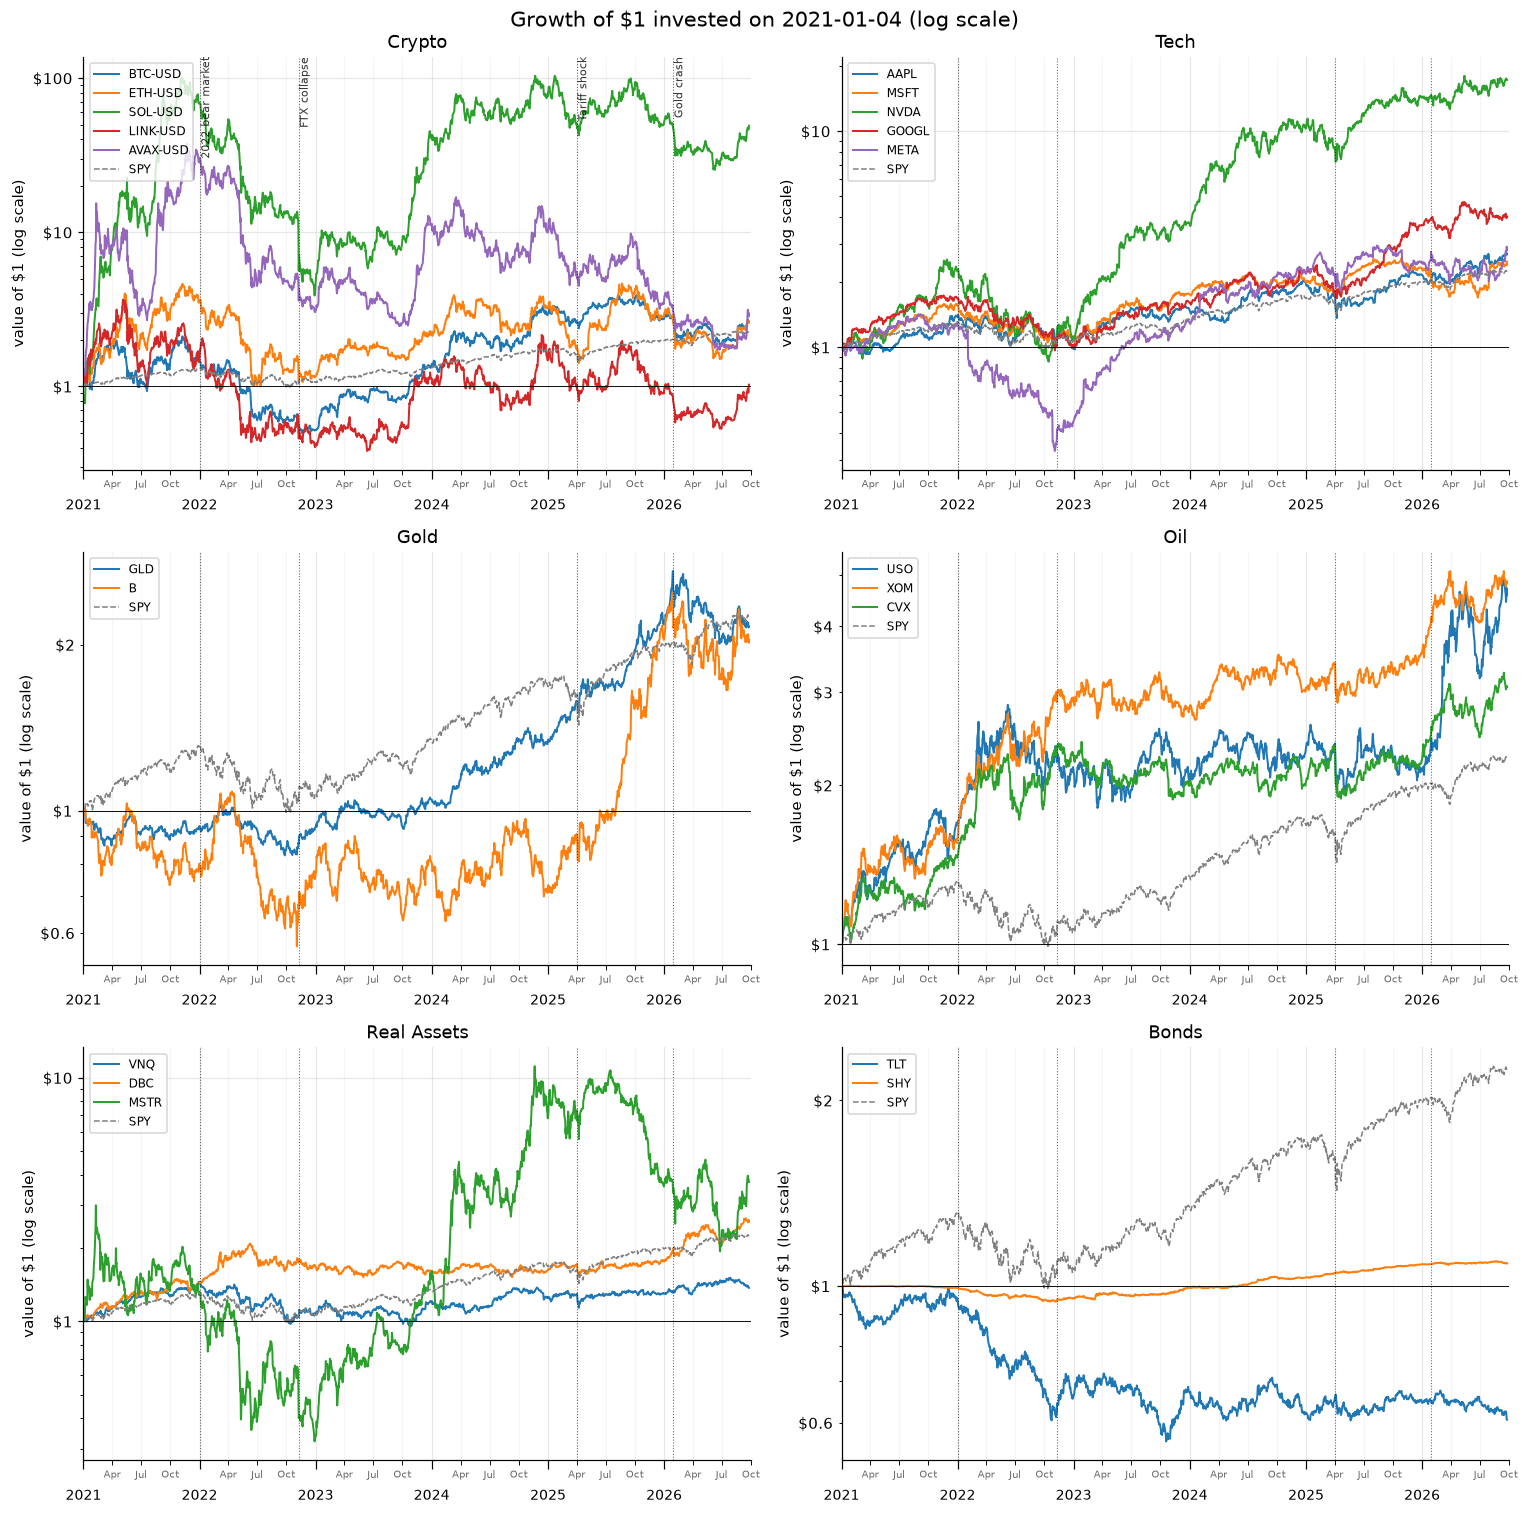

,class,final_value_$,total_return,CAGR,max_drawdown
SOL-USD,crypto,49.0966,48.0966,0.9785,-0.9612
NVDA,tech,17.2518,16.2518,0.6472,-0.6634
XOM,oil,4.8296,3.8296,0.3178,-0.2051
USO,oil,4.5809,3.5809,0.3057,-0.3623
GOOGL,tech,4.0228,3.0228,0.2763,-0.4432
MSTR,real_assets,3.7301,2.7301,0.2595,-0.8927
CVX,oil,3.0683,2.0683,0.2171,-0.2495
AVAX-USD,crypto,2.9670,1.9670,0.2100,-0.9538
META,tech,2.8217,1.8217,0.1994,-0.7674
AAPL,tech,2.7148,1.7148,0.1913,-0.3336


In [2]:
wealth = eda.wealth_index(simple)

fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=True)
for i, (ax, (cls, tickers)) in enumerate(zip(axes.flat, UNIVERSE.items())):
    for t in tickers:
        ax.plot(wealth.index, wealth[t], lw=1.3, label=t)
    ax.plot(wealth.index, wealth[BENCHMARK], color="grey", lw=1, ls="--", label="SPY")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(LogLabel(prefix="$"))
    ax.yaxis.set_minor_formatter(LogLabel(prefix="$"))
    ax.axhline(1, color="black", lw=0.6)
    ax.set_title(cls.replace("_", " ").title())
    mark_events(ax, label=(i == 0))
    format_time_axis(ax)
    ax.set_ylabel("value of $1 (log scale)")
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Growth of $1 invested on 2021-01-04 (log scale)", fontsize=14)
fig.tight_layout()
save_fig(fig, "g1_growth_of_1")
plt.show()

final = wealth.iloc[-1]
growth = pd.DataFrame({
    "class": pd.Series(CLASS_OF),
    "final_value_$": final,
    "total_return": final - 1,
    "CAGR": final ** (252 / T) - 1,
    "max_drawdown": (wealth / wealth.cummax() - 1).min(),
}).loc[ORDERED].sort_values("CAGR", ascending=False)
save_table(growth, "g1_growth")
growth

**Reading.** Huge dispersion in outcomes. SOL turned $1 into about $49, but at one point had fallen 96% from its peak. NVDA reached about $17. LINK ended roughly flat after a 90% drawdown, and TLT lost 39% (the 2022 rate shock). The regimes are visible: 2022 hit stocks, bonds and crypto at the same time; April 2025 is a sharp dip across equities; January 2026 shows in GLD and B. Assets inside a class move together (the crypto tokens, XOM/CVX), and MSTR looks like a crypto asset. No unexplained cliffs remain, so the data passes the final sanity check.

## Graph 2 — Rolling volatility over time

63-day rolling volatility $\hat\sigma^{(63)}_{i,t}\sqrt{252}$ and EWMA volatility ($\lambda = 0.94$), annualised.
**Looking for:** waves vs a flat line (clustering), spikes at known events, whether *relative* volatility between assets is stable, and how much faster EWMA reacts.

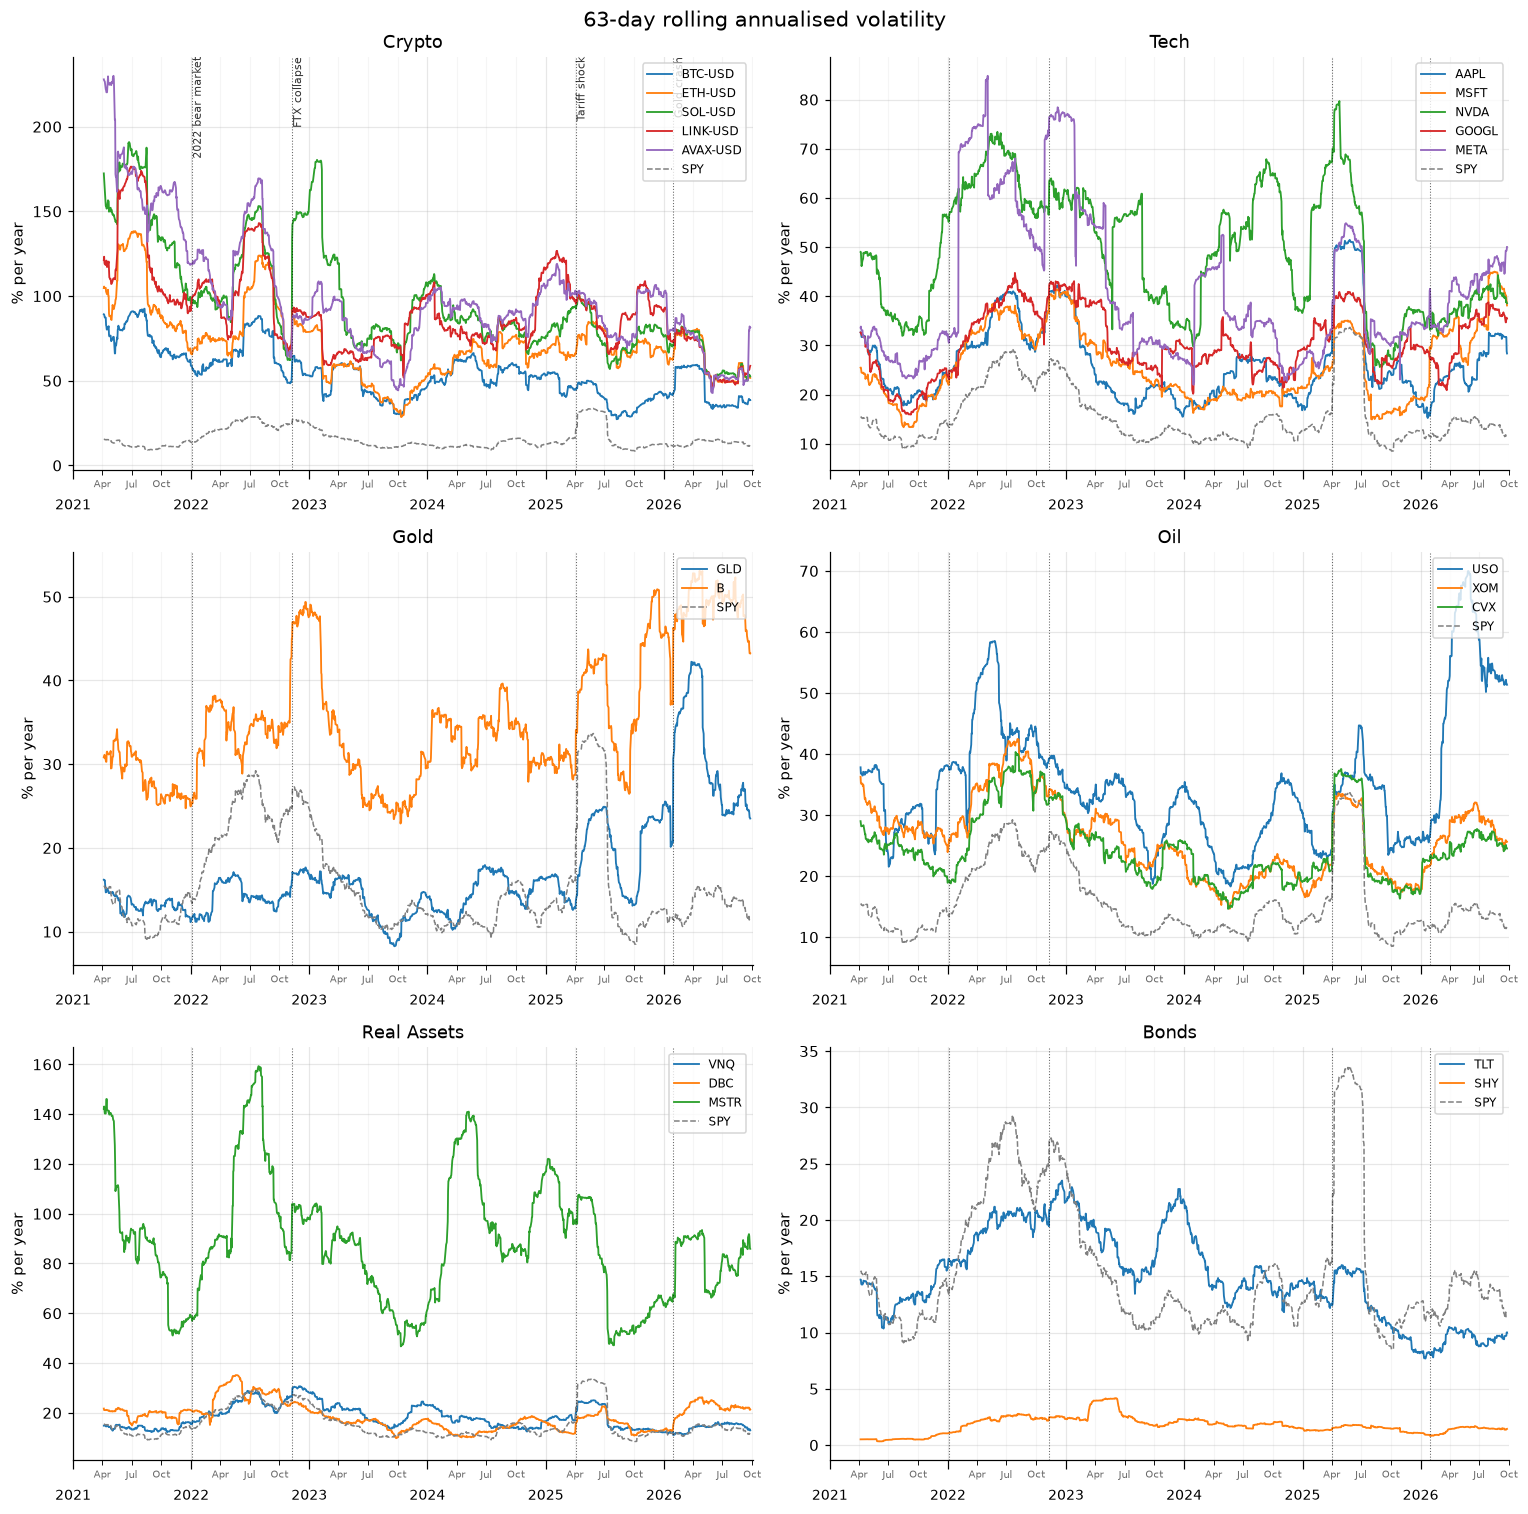

In [3]:
rv = eda.rolling_vol(logr, window=63)
ev = eda.ewma_vol(logr, lam=0.94)

fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=True)
for i, (ax, (cls, tickers)) in enumerate(zip(axes.flat, UNIVERSE.items())):
    for t in tickers:
        ax.plot(rv.index, rv[t] * 100, lw=1.2, label=t)
    ax.plot(rv.index, rv[BENCHMARK] * 100, color="grey", lw=1, ls="--", label="SPY")
    ax.set_ylabel("% per year")
    ax.set_title(cls.replace("_", " ").title())
    mark_events(ax, label=(i == 0))
    format_time_axis(ax)
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle("63-day rolling annualised volatility", fontsize=14)
fig.tight_layout()
save_fig(fig, "g2_rolling_vol")
plt.show()

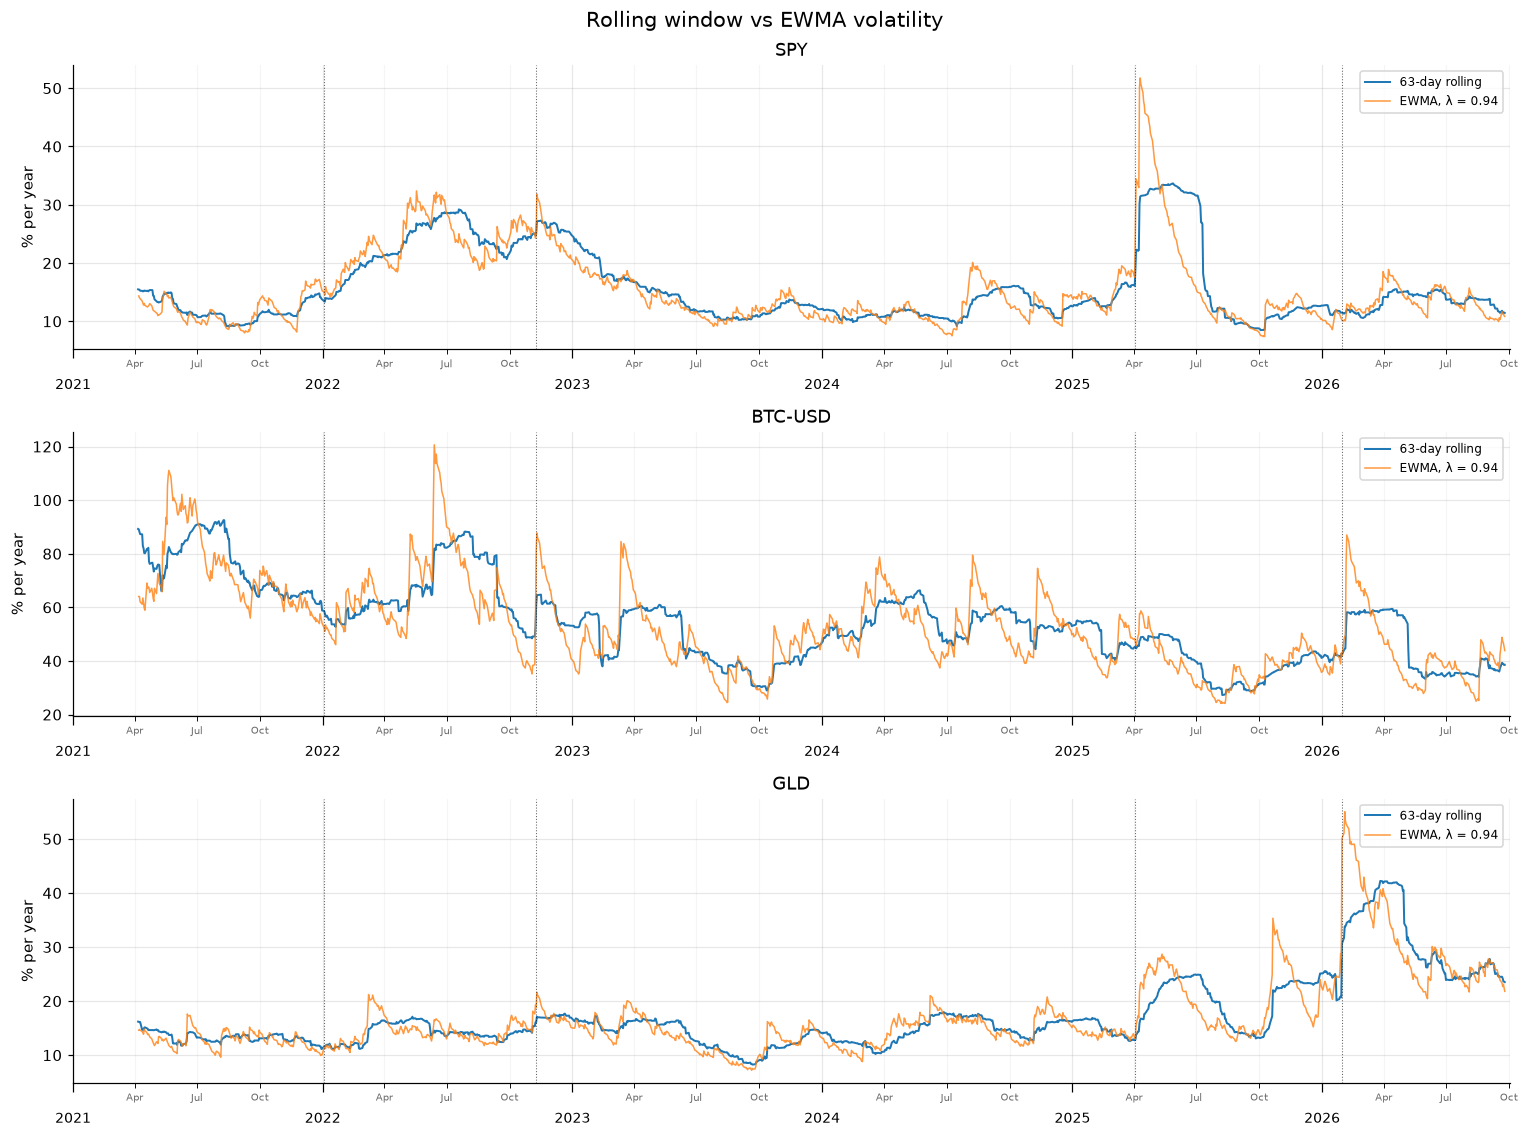

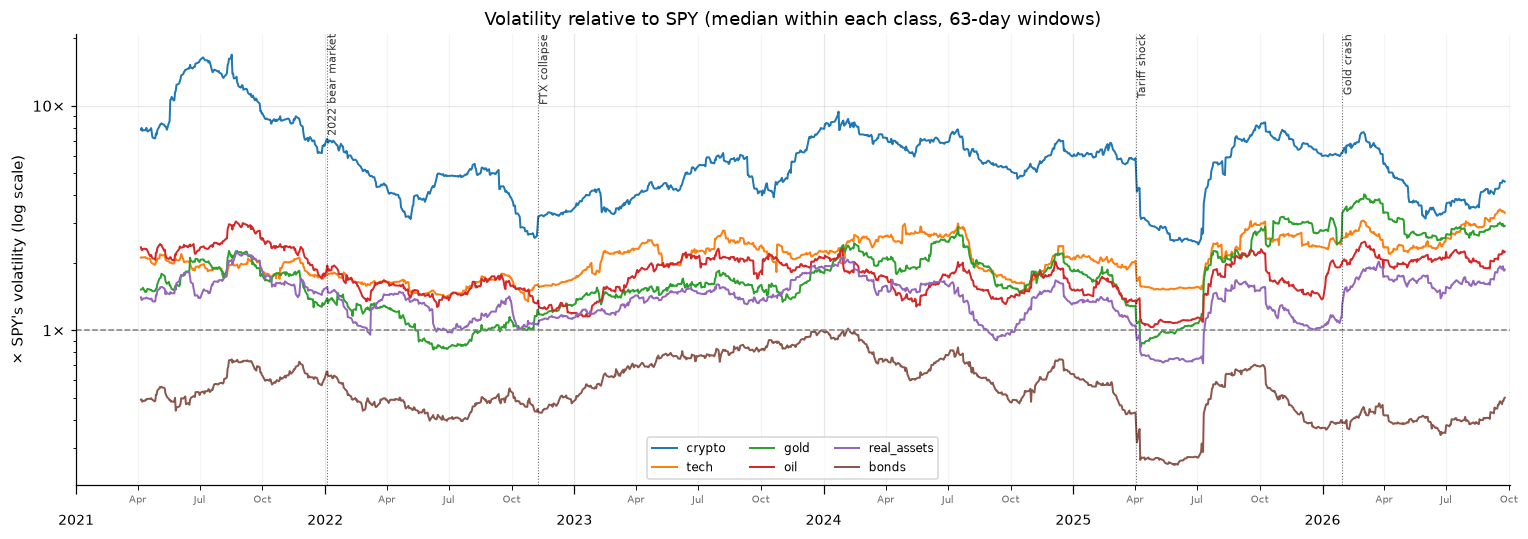

,class,min_63d_vol,median_63d_vol,max_63d_vol,max_over_min,ratio_to_spy_min,ratio_to_spy_max
BTC-USD,crypto,0.2728,0.5416,0.9255,3.3924,1.2330,9.7212
ETH-USD,crypto,0.2860,0.6944,1.3835,4.8379,2.1766,13.8363
SOL-USD,crypto,0.4500,0.8498,1.9094,4.2433,2.2269,20.4588
LINK-USD,crypto,0.4569,0.8682,1.7647,3.8622,2.4094,18.2562
AVAX-USD,crypto,0.4275,0.9409,2.3003,5.3803,2.5425,17.3890
AAPL,tech,0.1523,0.2378,0.5147,3.3804,1.2736,2.8804
MSFT,tech,0.1336,0.2403,0.4500,3.3692,0.9987,3.5607
NVDA,tech,0.2559,0.4858,0.7971,3.1152,1.7797,5.9098
GOOGL,tech,0.1595,0.2920,0.4475,2.8064,1.1876,3.1470
META,tech,0.2197,0.3476,0.8484,3.8615,1.5465,4.4355


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10.5), sharex=True)
for ax, t in zip(axes, ["SPY", "BTC-USD", "GLD"]):
    ax.plot(rv.index, rv[t] * 100, lw=1.3, label="63-day rolling")
    ax.plot(ev.index, ev[t] * 100, lw=1.0, alpha=0.8, label="EWMA, λ = 0.94")
    ax.set_title(t)
    ax.set_ylabel("% per year")
    mark_events(ax)
    format_time_axis(ax)
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle("Rolling window vs EWMA volatility", fontsize=14)
fig.tight_layout()
save_fig(fig, "g2_rolling_vs_ewma")
plt.show()

ratio = rv.div(rv[BENCHMARK], axis=0)
class_ratio = pd.DataFrame({cls: ratio[ts].median(axis=1) for cls, ts in UNIVERSE.items()})
fig, ax = plt.subplots(figsize=(14, 5))
for cls in class_ratio.columns:
    ax.plot(class_ratio.index, class_ratio[cls], lw=1.3, label=cls)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(LogLabel(suffix="×"))
ax.yaxis.set_minor_formatter(LogLabel(suffix="×"))
ax.axhline(1, color="grey", ls="--", lw=1)
mark_events(ax, label=True)
format_time_axis(ax)
ax.set_ylabel("× SPY's volatility (log scale)")
ax.set_title("Volatility relative to SPY (median within each class, 63-day windows)")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
save_fig(fig, "g2_vol_relative_to_spy")
plt.show()

vol_summary = pd.DataFrame({
    "class": pd.Series(CLASS_OF),
    "min_63d_vol": rv.min(),
    "median_63d_vol": rv.median(),
    "max_63d_vol": rv.max(),
    "max_over_min": rv.max() / rv.min(),
    "ratio_to_spy_min": ratio.min(),
    "ratio_to_spy_max": ratio.max(),
}).loc[ORDERED]
save_table(vol_summary, "g2_vol_summary")
vol_summary

**Reading.** Volatility clearly comes in waves. Every asset's 63-day volatility ranges about 3–5× between its calmest and wildest quarter (SHY 13×). The spikes line up with known events: 2022, FTX (SOL near 180%), the April 2025 tariff shock (SPY about 34%), and the January 2026 gold crash (GLD about 42%). Relative volatility is not stable either: BTC ranges from 1.2× to 9.7× SPY's volatility, GLD from 0.5× to 3.6×. EWMA reacts within days, while the 63-day window reacts slowly and then drops off a cliff exactly 63 days after a shock (a 'ghost' of the old shock leaving the window). Conclusion: vol-scaling needs a time-varying σ, and EWMA is the better candidate.

## Graph 3 — Distributions and fat tails

Standardised returns $z_t = (r_t - \bar r)/s$. Skewness $\frac1T\sum z^3$, excess kurtosis $\frac1T\sum z^4 - 3$, Jarque–Bera $\frac{T}{6}(S^2 + (K-3)^2/4)$.
**Looking for:** how fat the tails are, the sign of skew, and how much of the fat-tailedness disappears after dividing by the *previous day's* EWMA volatility.

In [5]:
moments = eda.moments_table(logr).loc[ORDERED]
moments.insert(0, "class", pd.Series(CLASS_OF))
save_table(moments, "g3_moments")
moments.round(3)

,class,ann_mean,ann_vol,skew,excess_kurt,jb_stat,jb_pvalue,worst_z,best_z
BTC-USD,crypto,0.1690,0.5730,-0.2690,4.6760,"1,327.3920",0.0000,-7.1430,5.2860
ETH-USD,crypto,0.1670,0.7610,-0.4270,5.2270,"1,681.0160",0.0000,-6.7690,5.1420
SOL-USD,crypto,0.6820,1.0550,-0.3600,7.2270,"3,160.7870",0.0000,-8.3110,4.9210
LINK-USD,crypto,0.0040,0.9480,-0.4250,5.1630,"1,640.4560",0.0000,-7.8040,5.5290
AVAX-USD,crypto,0.1910,1.1220,0.3440,8.1950,"4,052.0760",0.0000,-6.4380,7.9100
AAPL,tech,0.1750,0.2760,0.1410,5.2560,"1,660.1560",0.0000,-5.6120,8.1520
MSFT,tech,0.1600,0.2720,0.3240,6.1460,"2,288.0150",0.0000,-6.1770,8.3700
NVDA,tech,0.4990,0.5030,0.2290,3.6710,820.0040,0.0000,-5.9320,6.8220
GOOGL,tech,0.2440,0.3130,0.0180,3.1130,580.5300,0.0000,-5.1240,4.8940
META,tech,0.1820,0.4390,-1.0190,23.3840,"33,011.3090",0.0000,-11.1140,7.5480


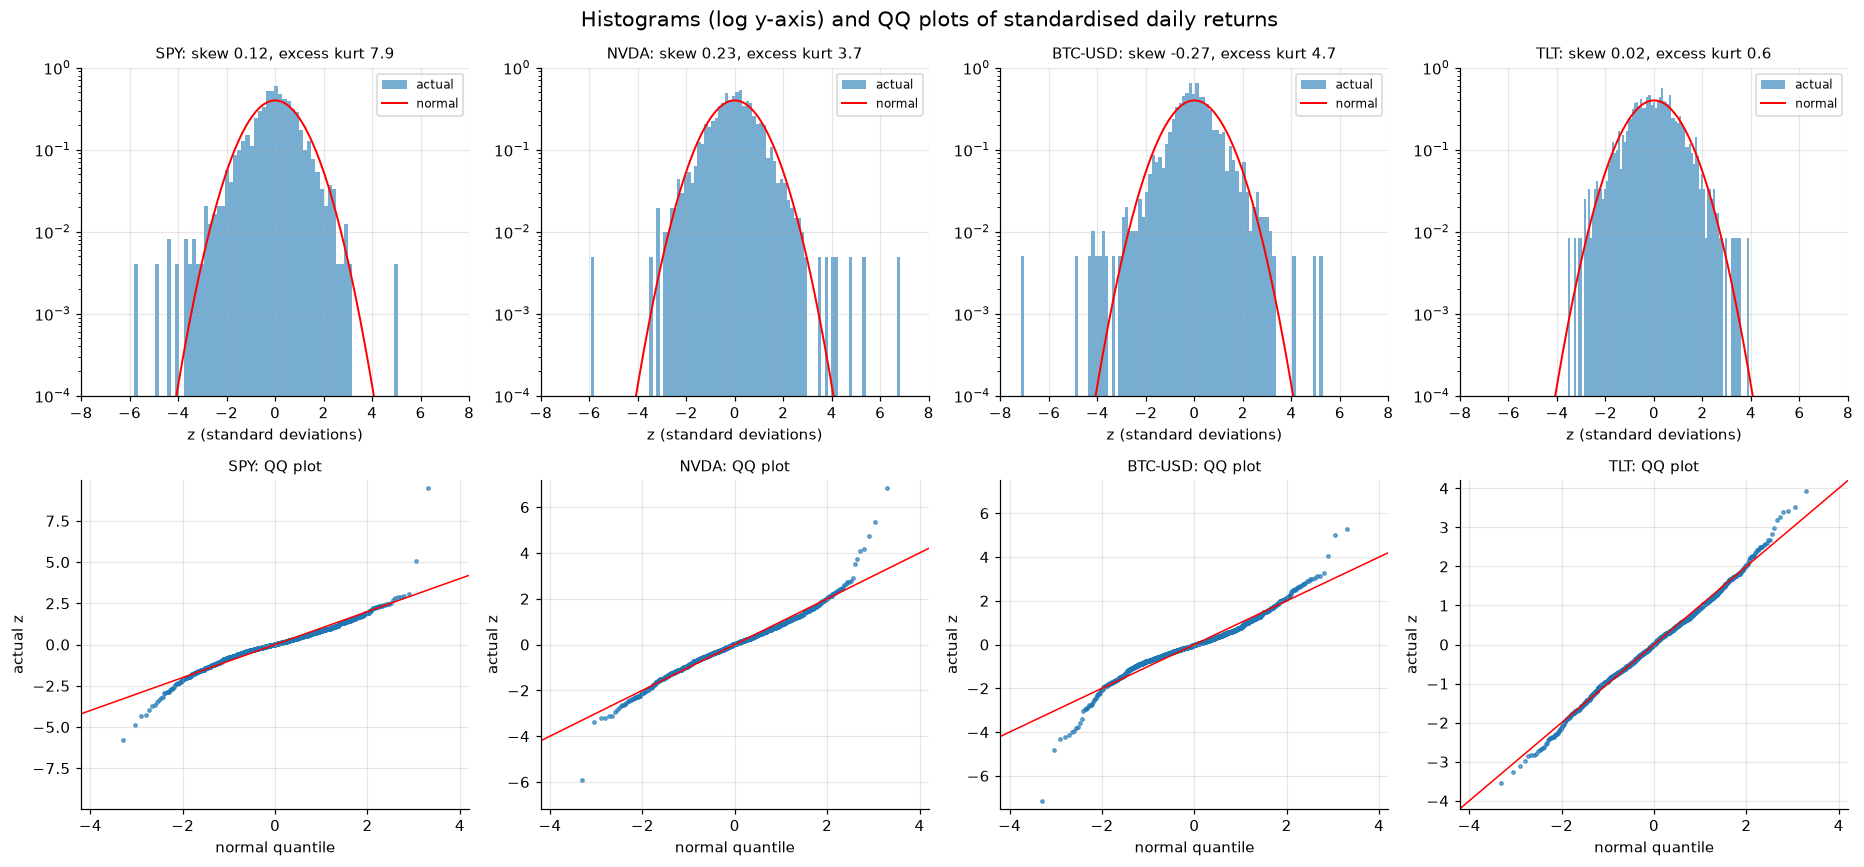

In [6]:
reps = ["SPY", "NVDA", "BTC-USD", "TLT"]
x = np.linspace(-8, 8, 400)
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for j, t in enumerate(reps):
    r = logr[t]
    z = (r - r.mean()) / r.std()
    ax = axes[0, j]
    ax.hist(z, bins=90, density=True, alpha=0.6, label="actual")
    ax.plot(x, stats.norm.pdf(x), color="red", lw=1.3, label="normal")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1)
    ax.set_xlim(-8, 8)
    ax.set_title(f"{t}: skew {stats.skew(r):.2f}, excess kurt {stats.kurtosis(r):.1f}", fontsize=10)
    ax.set_xlabel("z (standard deviations)")
    ax.legend(fontsize=8)

    (osm, osr), _ = stats.probplot(z, dist="norm")
    ax2 = axes[1, j]
    ax2.scatter(osm, osr, s=5, alpha=0.6)
    lim = max(abs(osr).max(), 4) * 1.05
    ax2.plot([-lim, lim], [-lim, lim], color="red", lw=1)
    ax2.set_xlim(-4.2, 4.2)
    ax2.set_ylim(-lim, lim)
    ax2.set_xlabel("normal quantile")
    ax2.set_ylabel("actual z")
    ax2.set_title(f"{t}: QQ plot", fontsize=10)
fig.suptitle("Histograms (log y-axis) and QQ plots of standardised daily returns", fontsize=14)
fig.tight_layout()
save_fig(fig, "g3_hist_qq")
plt.show()

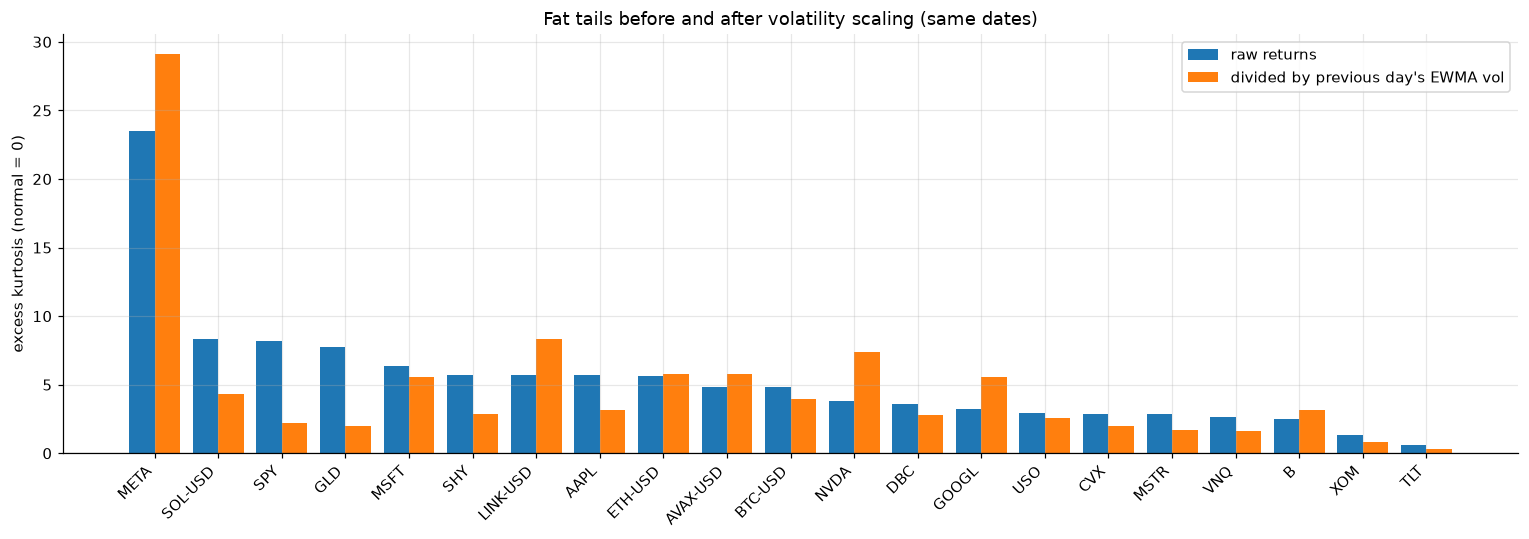

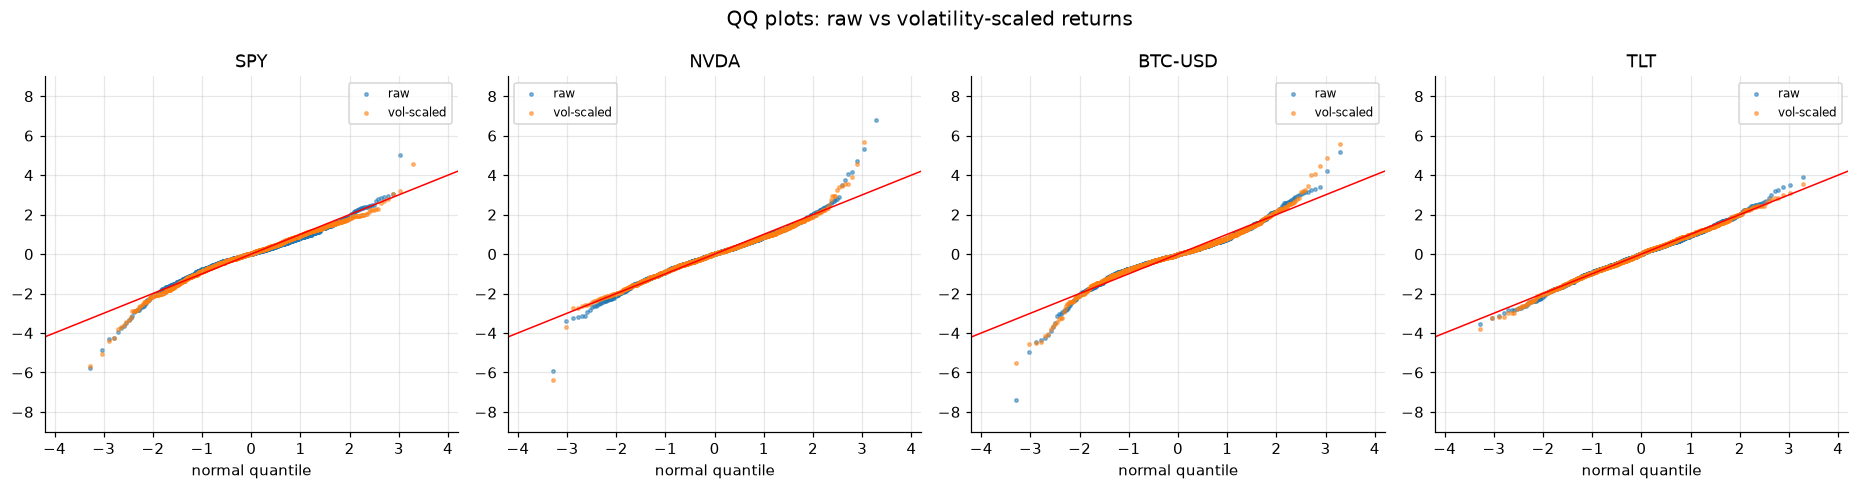

,class,kurt_raw,kurt_scaled,skew_raw,skew_scaled,worst_z_raw,worst_z_scaled,kurt_reduction
BTC-USD,crypto,4.8600,3.9400,-0.3600,-0.0700,-7.3800,-5.5100,0.1900
ETH-USD,crypto,5.6400,5.8100,-0.4500,0.0800,-6.9100,-5.6200,-0.0300
SOL-USD,crypto,8.3700,4.3300,-0.6000,-0.3300,-8.6700,-7.4200,0.4800
LINK-USD,crypto,5.7100,8.3700,-0.4600,0.3800,-7.9200,-4.8700,-0.4700
AVAX-USD,crypto,4.8600,5.7800,-0.3600,0.0500,-6.9700,-6.0300,-0.1900
AAPL,tech,5.6900,3.1400,0.1500,-0.2200,-5.6600,-5.4400,0.4500
MSFT,tech,6.3700,5.5400,0.3400,-0.1000,-6.1500,-6.7800,0.1300
NVDA,tech,3.7900,7.3900,0.2500,0.6200,-5.9200,-6.4000,-0.9500
GOOGL,tech,3.1900,5.5300,0.0000,-0.0900,-5.1300,-6.9700,-0.7300
META,tech,23.5200,29.1100,-1.0300,-0.4700,-11.0000,-11.6400,-0.2400


In [7]:
scaled = eda.vol_scaled_returns(logr, lam=0.94)
same_dates = logr.loc[scaled.index]
raw_m = eda.moments_table(same_dates)
scaled_m = eda.moments_table(scaled)

kurt_cmp = pd.DataFrame({
    "class": pd.Series(CLASS_OF),
    "kurt_raw": raw_m["excess_kurt"],
    "kurt_scaled": scaled_m["excess_kurt"],
    "skew_raw": raw_m["skew"],
    "skew_scaled": scaled_m["skew"],
    "worst_z_raw": raw_m["worst_z"],
    "worst_z_scaled": scaled_m["worst_z"],
}).loc[ORDERED]
kurt_cmp["kurt_reduction"] = 1 - kurt_cmp["kurt_scaled"] / kurt_cmp["kurt_raw"]
save_table(kurt_cmp, "g3_kurtosis_before_after_scaling")

order = kurt_cmp.sort_values("kurt_raw", ascending=False).index
fig, ax = plt.subplots(figsize=(14, 5))
pos = np.arange(len(order))
ax.bar(pos - 0.2, kurt_cmp.loc[order, "kurt_raw"], width=0.4, label="raw returns")
ax.bar(pos + 0.2, kurt_cmp.loc[order, "kurt_scaled"], width=0.4, label="divided by previous day's EWMA vol")
ax.set_xticks(pos)
ax.set_xticklabels(order, rotation=45, ha="right")
ax.axhline(0, color="black", lw=0.7)
ax.set_ylabel("excess kurtosis (normal = 0)")
ax.set_title("Fat tails before and after volatility scaling (same dates)")
ax.legend()
fig.tight_layout()
save_fig(fig, "g3_kurtosis_before_after")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, t in zip(axes, reps):
    for series, lab in [(same_dates[t], "raw"), (scaled[t], "vol-scaled")]:
        z = (series - series.mean()) / series.std()
        (osm, osr), _ = stats.probplot(z.dropna(), dist="norm")
        ax.scatter(osm, osr, s=5, alpha=0.5, label=lab)
    ax.plot([-6, 6], [-6, 6], color="red", lw=1)
    ax.set_xlim(-4.2, 4.2)
    ax.set_ylim(-9, 9)
    ax.set_title(t)
    ax.set_xlabel("normal quantile")
    ax.legend(fontsize=8)
fig.suptitle("QQ plots: raw vs volatility-scaled returns", fontsize=13)
fig.tight_layout()
save_fig(fig, "g3_qq_raw_vs_scaled")
plt.show()

kurt_cmp.round(2)

**Reading.** All 21 assets are fat-tailed: Jarque–Bera rejects normality everywhere, and excess kurtosis ranges from 0.6 (TLT) to 23 (META, whose −26% earnings day is an 11σ event). Skew is small and mixed: slightly negative for crypto, oil, gold and commodities, slightly positive for most tech and SPY. Because skew cubes returns, it is driven by a handful of days (SPY's +9.5σ tariff-pause rebound on 9 April 2025), so it is not a stable property. Dividing by the previous day's EWMA volatility cuts median kurtosis by 22%. The cut is strong for SPY (8.2 → 2.2), GLD (7.8 → 2.0), AAPL, SOL and SHY, whose fat tails are mostly calm/storm switching. For NVDA, GOOGL and META kurtosis rises: their biggest moves are earnings or news jumps that arrive in calm periods, so dividing by a low prior volatility makes them look even more extreme. Vol-scaling fixes regime-driven tails, not jump risk, so rank-based measures remain necessary.

## Graph 4 — Correlation structure

Pearson $\rho = \mathrm{Cov}/(s_X s_Y)$ and Spearman (Pearson on ranks). Effective bets $N_{eff} = N/(1+(N-1)\bar\rho)$.
**Looking for:** hidden blocks, diversifiers, how many real bets the 20 tradeables contain, and whether correlation spikes in stress periods.

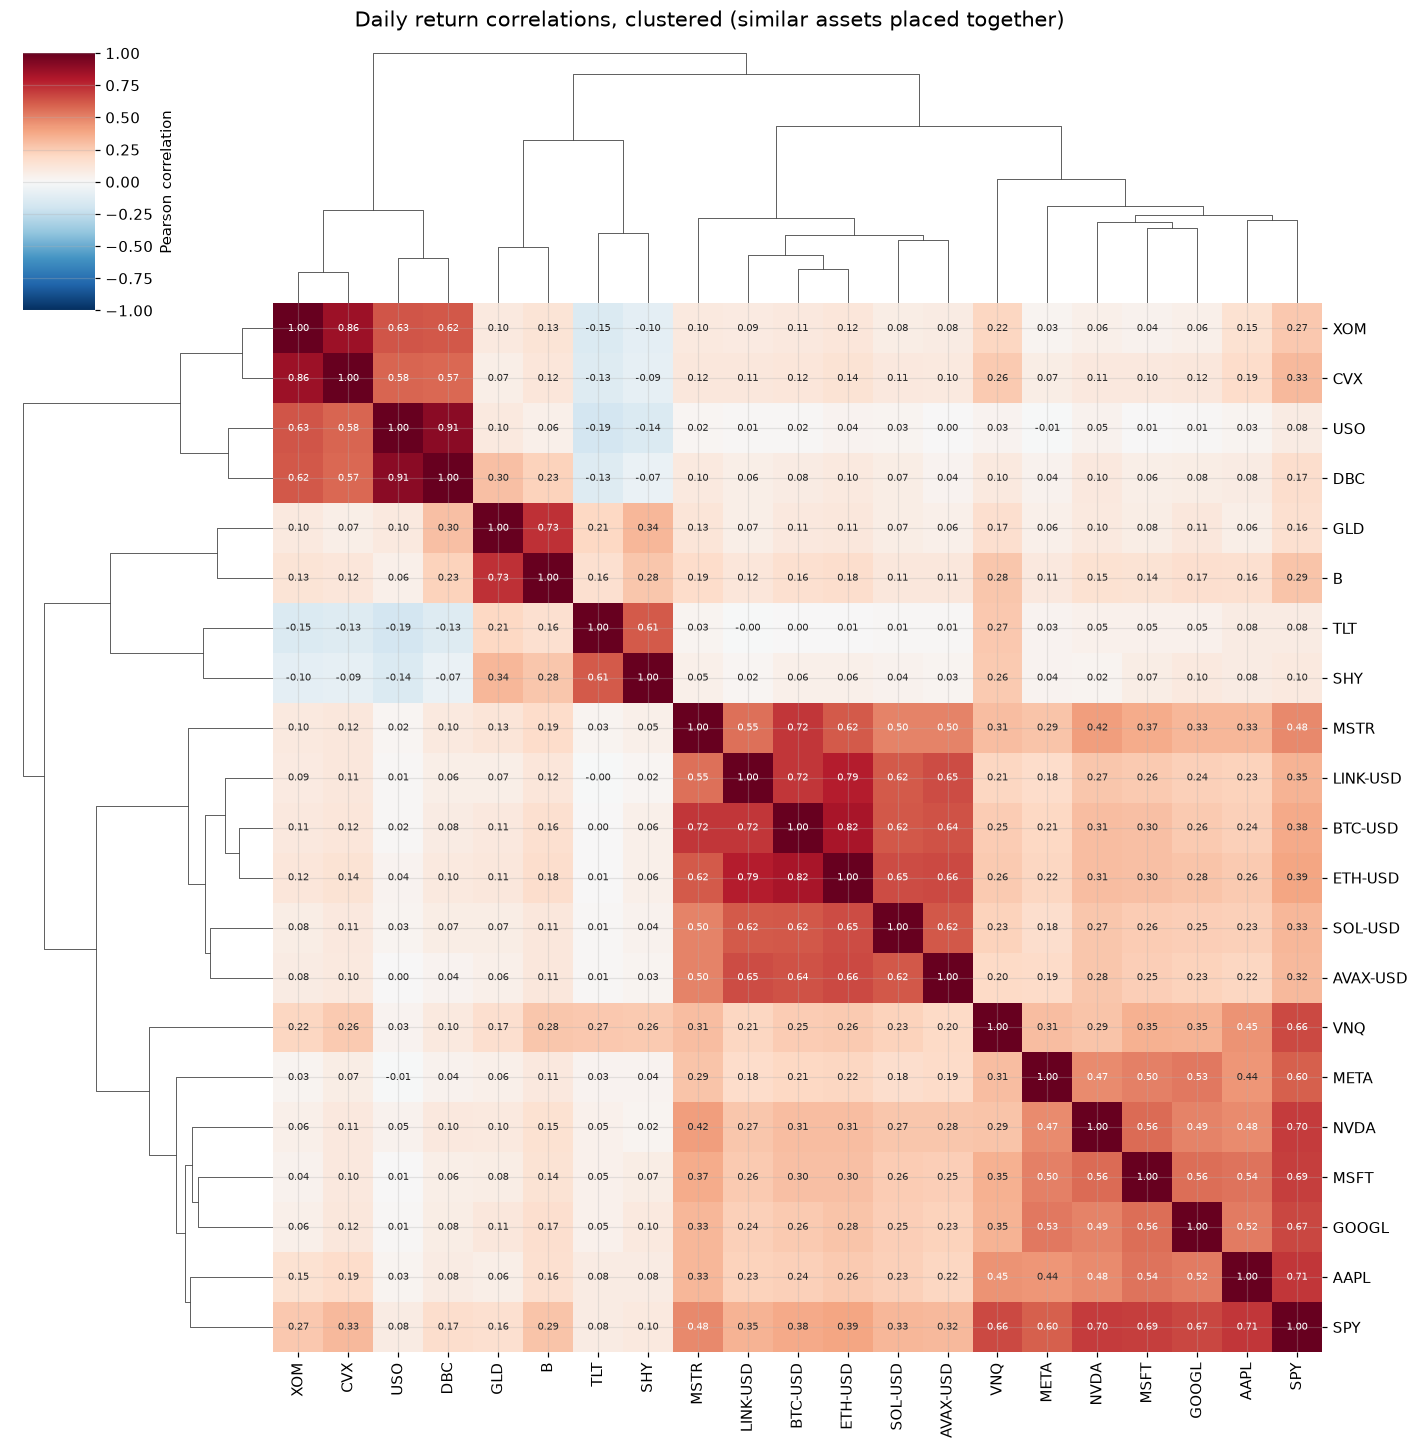

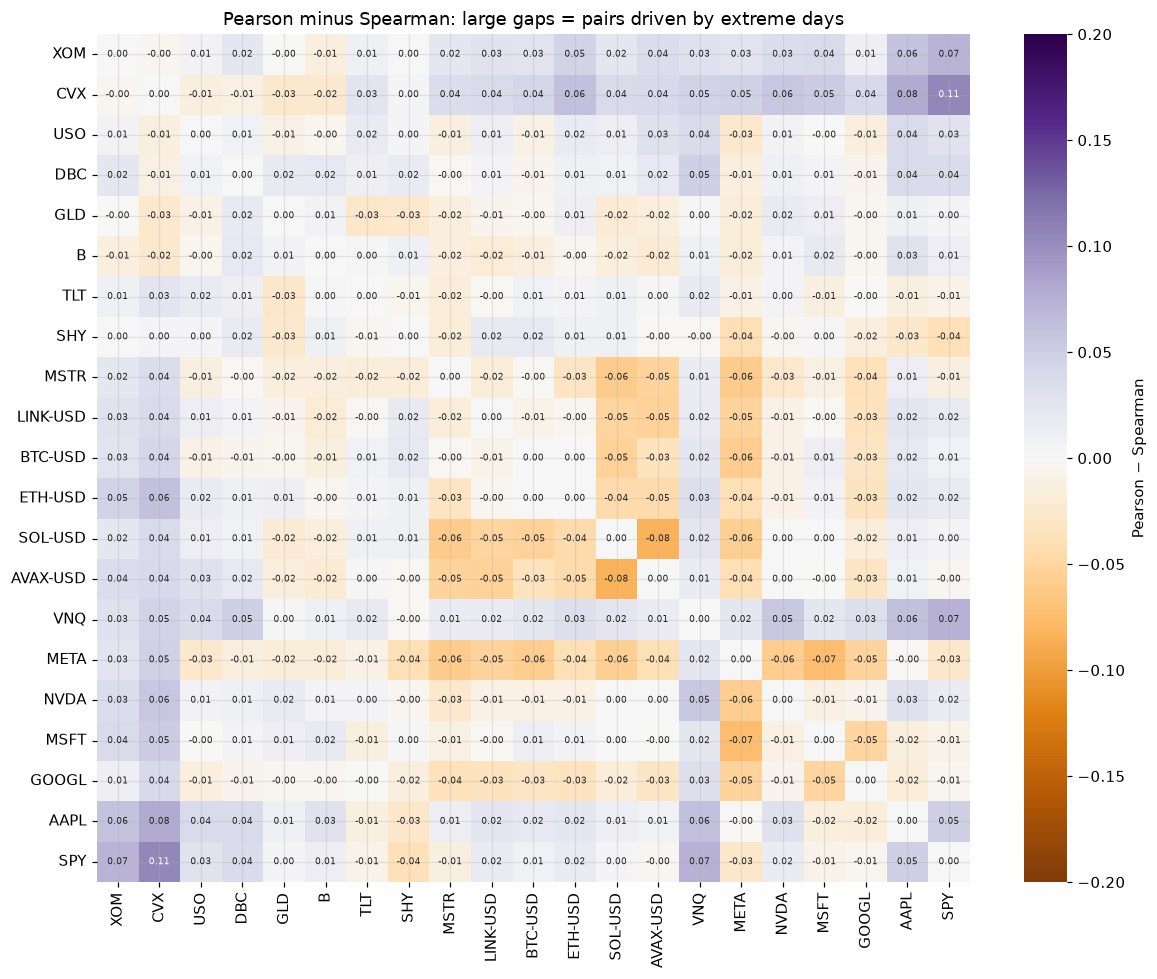

In [8]:
pearson = logr[ORDERED].corr()
spearman = logr[ORDERED].corr(method="spearman")

cg = sns.clustermap(pearson, cmap="RdBu_r", vmin=-1, vmax=1, center=0, method="average",
                    annot=True, fmt=".2f", annot_kws={"size": 6.5}, figsize=(13, 13),
                    cbar_kws={"label": "Pearson correlation"})
cg.fig.suptitle("Daily return correlations, clustered (similar assets placed together)", fontsize=14, y=1.01)
save_fig(cg.fig, "g4_corr_clustered")
plt.show()

cluster_order = [pearson.columns[i] for i in cg.dendrogram_row.reordered_ind]
diff = (pearson - spearman).loc[cluster_order, cluster_order]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(diff, cmap="PuOr", center=0, vmin=-0.2, vmax=0.2, annot=True, fmt=".2f", annot_kws={"size": 6}, ax=ax,
            cbar_kws={"label": "Pearson − Spearman"})
ax.set_title("Pearson minus Spearman: large gaps = pairs driven by extreme days")
fig.tight_layout()
save_fig(fig, "g4_pearson_minus_spearman")
plt.show()

Average pairwise correlation (20 tradeables): Pearson 0.215, Spearman 0.214
Effective number of bets: 3.9 (Pearson), 3.9 (Spearman) out of 20


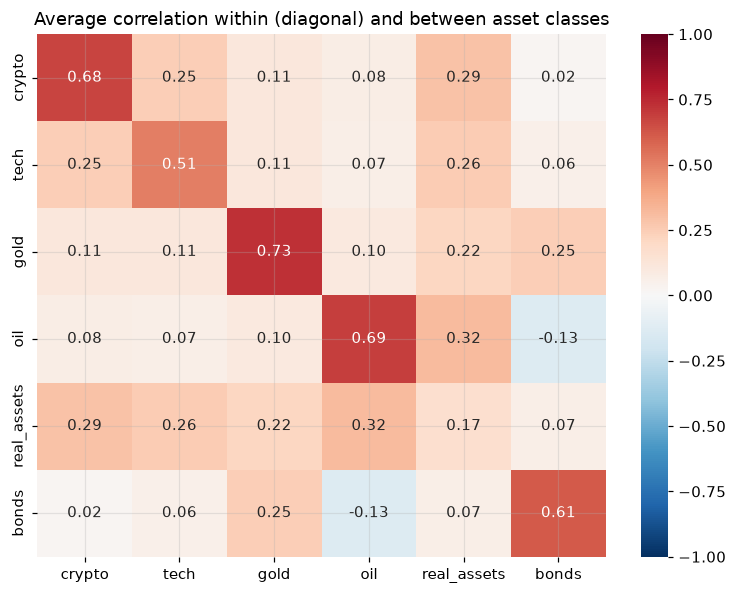

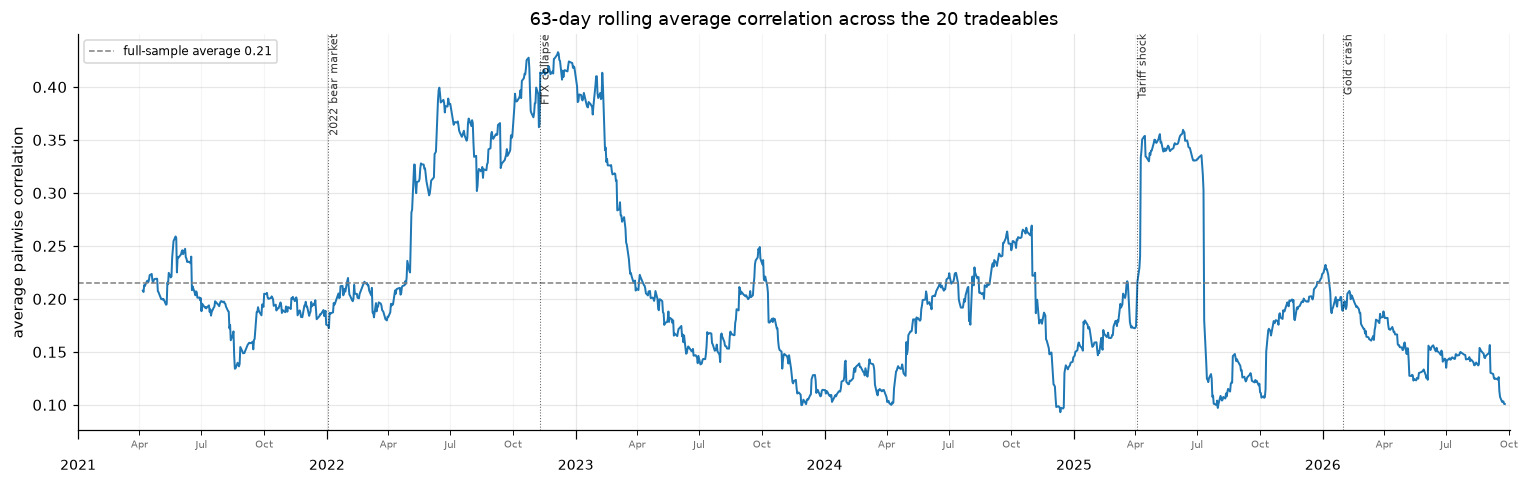

,crypto,tech,gold,oil,real_assets,bonds
crypto,0.6800,0.2500,0.1100,0.0800,0.2900,0.0200
tech,0.2500,0.5100,0.1100,0.0700,0.2600,0.0600
gold,0.1100,0.1100,0.7300,0.1000,0.2200,0.2500
oil,0.0800,0.0700,0.1000,0.6900,0.3200,-0.1300
real_assets,0.2900,0.2600,0.2200,0.3200,0.1700,0.0700
bonds,0.0200,0.0600,0.2500,-0.1300,0.0700,0.6100


In [9]:
trade = logr[TRADEABLES]
avg_p = eda.average_pairwise_corr(trade.corr())
avg_s = eda.average_pairwise_corr(trade.corr(method="spearman"))
n = len(TRADEABLES)
print(f"Average pairwise correlation (20 tradeables): Pearson {avg_p:.3f}, Spearman {avg_s:.3f}")
print(f"Effective number of bets: {eda.effective_bets(n, avg_p):.1f} (Pearson), {eda.effective_bets(n, avg_s):.1f} (Spearman) out of {n}")

classes = list(UNIVERSE)
block = pd.DataFrame(index=classes, columns=classes, dtype=float)
c = trade.corr()
for a in classes:
    for b in classes:
        sub = c.loc[UNIVERSE[a], UNIVERSE[b]].to_numpy()
        if a == b:
            sub = sub[~np.eye(len(sub), dtype=bool)]
        block.loc[a, b] = sub.mean()
save_table(block, "g4_class_block_corr")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(block, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Average correlation within (diagonal) and between asset classes")
fig.tight_layout()
save_fig(fig, "g4_class_block_corr")
plt.show()

roll_corr = eda.rolling_average_corr(trade, window=63)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(roll_corr.index, roll_corr, lw=1.3)
ax.axhline(avg_p, color="grey", ls="--", lw=1, label=f"full-sample average {avg_p:.2f}")
mark_events(ax, label=True)
format_time_axis(ax)
ax.set_ylabel("average pairwise correlation")
ax.set_title("63-day rolling average correlation across the 20 tradeables")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "g4_rolling_avg_corr")
plt.show()
save_table(roll_corr.to_frame(), "g4_rolling_avg_corr")
block.round(2)

**Reading.** Average pairwise correlation is 0.21, so the 20 tradeables behave like about 3.9 independent bets. There are five clear blocks. Crypto plus MSTR (0.50–0.82; MSTR–BTC 0.72, so MSTR behaves like crypto, not a 'real asset'). Oil (XOM–CVX 0.86; USO–DBC 0.91, so DBC is mostly an oil fund). Gold (GLD–B 0.73). Bonds (TLT–SHY 0.61). US equities (tech, VNQ, SPY). The 'real assets' label is not a real block (within-class 0.17). Oil and bonds are slightly negatively correlated (−0.13). Pearson and Spearman averages are almost identical (0.215 vs 0.214). Rolling average correlation has a median of 0.19, but rose to 0.31 on average in 2022 (peak about 0.43 around FTX) and to 0.32–0.36 in the tariff shock: diversification weakens in stress.

## Graph 5 — Autocorrelation of daily returns (the key graph)

$\hat\rho_k = \mathrm{corr}(r_t, r_{t-k})$, lags 1–10. Grey band: Bartlett $\pm 1.96/\sqrt{T}$. Dashed lines: **robust** band $\pm 1.96 \times$ heteroskedasticity-robust SE, which accounts for volatility clustering.
**Looking for:** the sign at short lags by class (momentum +, reversal −), consistency across related assets, size ($R^2 = \rho_1^2$), and whether 3-day blocks show more structure.

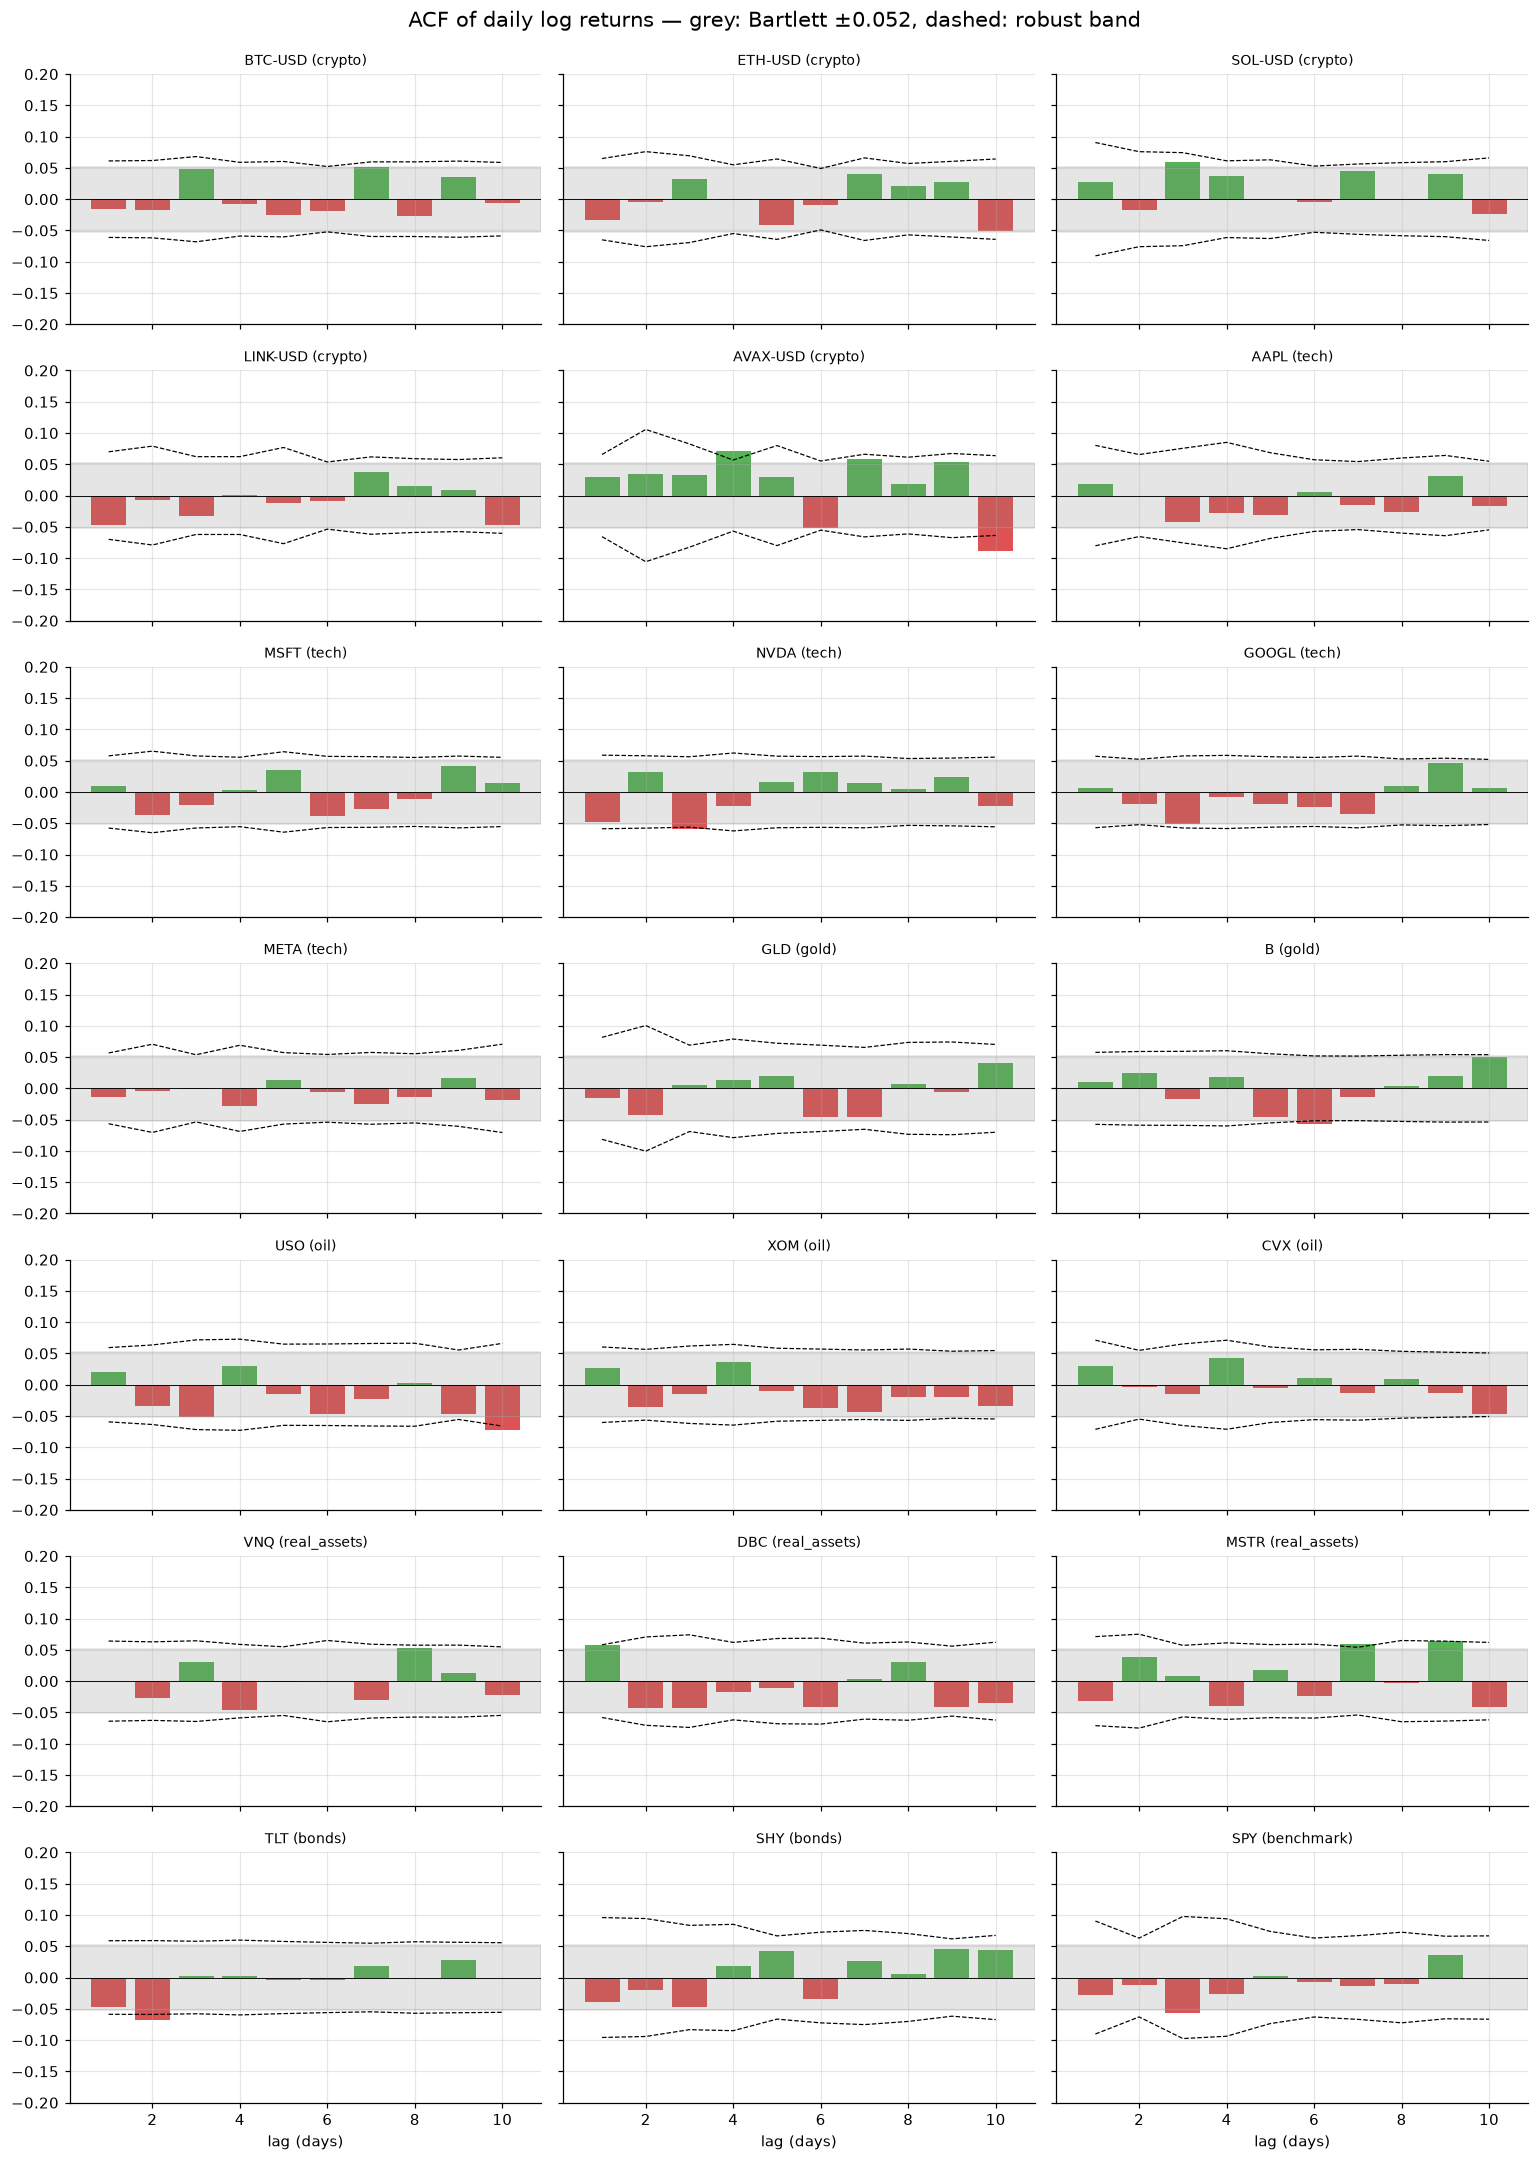

In [10]:
NL = 10
acf1 = eda.acf_table(logr[ORDERED], NL)
se_rob = eda.robust_acf_se(logr[ORDERED], NL)
band = eda.acf_band(T)

fig, axes = plt.subplots(7, 3, figsize=(14, 20), sharex=True, sharey=True)
lags = np.arange(1, NL + 1)
for ax, t in zip(axes.flat, ORDERED):
    vals = acf1.loc[t].to_numpy()
    ax.bar(lags, vals, color=np.where(vals > 0, "tab:green", "tab:red"), alpha=0.8)
    ax.axhspan(-band, band, color="grey", alpha=0.2)
    ax.plot(lags, 1.96 * se_rob.loc[t], color="black", ls="--", lw=0.8)
    ax.plot(lags, -1.96 * se_rob.loc[t], color="black", ls="--", lw=0.8)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{t} ({CLASS_OF[t]})", fontsize=9)
    ax.set_ylim(-0.2, 0.2)
for ax in axes[-1]:
    ax.set_xlabel("lag (days)")
fig.suptitle(f"ACF of daily log returns — grey: Bartlett ±{band:.3f}, dashed: robust band", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save_fig(fig, "g5_acf_daily")
plt.show()

In [11]:
lb = eda.ljung_box_table(logr[ORDERED], lags=(5, 10))
acf_tbl = pd.DataFrame({
    "class": pd.Series(CLASS_OF),
    "rho1": acf1[1], "rho2": acf1[2], "rho3": acf1[3],
    "robust_t_rho1": acf1[1] / se_rob[1],
    "Q(5)": lb["Q(5)"], "p(5)": lb["p(5)"], "Q(10)": lb["Q(10)"], "p(10)": lb["p(10)"],
    "VR(3)": acf1.apply(lambda row: eda.variance_ratio(row, 3), axis=1),
    "n_sig_bartlett": (acf1.abs() > band).sum(axis=1),
    "n_sig_robust": (acf1.abs() > 1.96 * se_rob).sum(axis=1),
}).loc[ORDERED]
save_table(acf_tbl, "g5_acf_daily_table")

by_class = acf_tbl.groupby("class").agg(
    mean_rho1=("rho1", "mean"), share_rho1_negative=("rho1", lambda s: (s < 0).mean()),
    mean_VR3=("VR(3)", "mean"), sig_bartlett=("n_sig_bartlett", "sum"), sig_robust=("n_sig_robust", "sum"),
)
save_table(by_class, "g5_acf_by_class")

n_tests = len(ORDERED) * NL
print(f"Significant bars: Bartlett {acf_tbl['n_sig_bartlett'].sum()}, robust {acf_tbl['n_sig_robust'].sum()} "
      f"out of {n_tests} tests (≈{0.05 * n_tests:.1f} expected by pure chance)")
print(f"Largest |rho1|: {acf_tbl['rho1'].abs().max():.3f} ({acf_tbl['rho1'].abs().idxmax()}) -> R² = {acf_tbl['rho1'].abs().max()**2:.2%}")
display(by_class.round(3))
acf_tbl.round(3)

Significant bars: Bartlett 14, robust 9 out of 210 tests (≈10.5 expected by pure chance)
Largest |rho1|: 0.058 (DBC) -> R² = 0.34%


,mean_rho1,share_rho1_negative,mean_VR3,sig_bartlett,sig_robust
class,,,,,
benchmark,-0.0280,1.0000,0.9540,1,0
bonds,-0.0430,1.0000,0.9130,1,1
crypto,-0.0080,0.6000,0.9880,5,2
gold,-0.0030,0.5000,0.9900,1,1
oil,0.0260,0.0000,1.0190,1,1
real_assets,0.0090,0.3330,1.0050,4,3
tech,-0.0060,0.4000,0.9890,1,1


,class,rho1,rho2,rho3,robust_t_rho1,Q(5),p(5),Q(10),p(10),VR(3),n_sig_bartlett,n_sig_robust
BTC-USD,crypto,-0.0160,-0.0170,0.0480,-0.5180,5.1770,0.3950,12.4320,0.2570,0.9670,0,0
ETH-USD,crypto,-0.0330,-0.0040,0.0320,-0.9980,5.6140,0.3460,13.3770,0.2030,0.9530,0,0
SOL-USD,crypto,0.0280,-0.0170,0.0600,0.5950,8.6610,0.1230,14.7590,0.1410,1.0250,1,0
LINK-USD,crypto,-0.0470,-0.0070,-0.0330,-1.3280,5.1160,0.4020,10.9700,0.3600,0.9320,0,0
AVAX-USD,crypto,0.0300,0.0350,0.0330,0.8960,13.1350,0.0220,37.7100,0.0000,1.0630,4,2
AAPL,tech,0.0180,-0.0000,-0.0420,0.4500,5.5470,0.3530,8.6120,0.5690,1.0240,0,0
MSFT,tech,0.0090,-0.0370,-0.0200,0.2980,4.5870,0.4680,10.7710,0.3760,0.9870,0,0
NVDA,tech,-0.0480,0.0320,-0.0600,-1.6000,11.0290,0.0510,14.5150,0.1510,0.9570,1,1
GOOGL,tech,0.0070,-0.0190,-0.0510,0.2340,4.9730,0.4190,11.0050,0.3570,0.9960,0,0
META,tech,-0.0140,-0.0040,-0.0010,-0.4840,1.7050,0.8880,3.7770,0.9570,0.9790,0,0


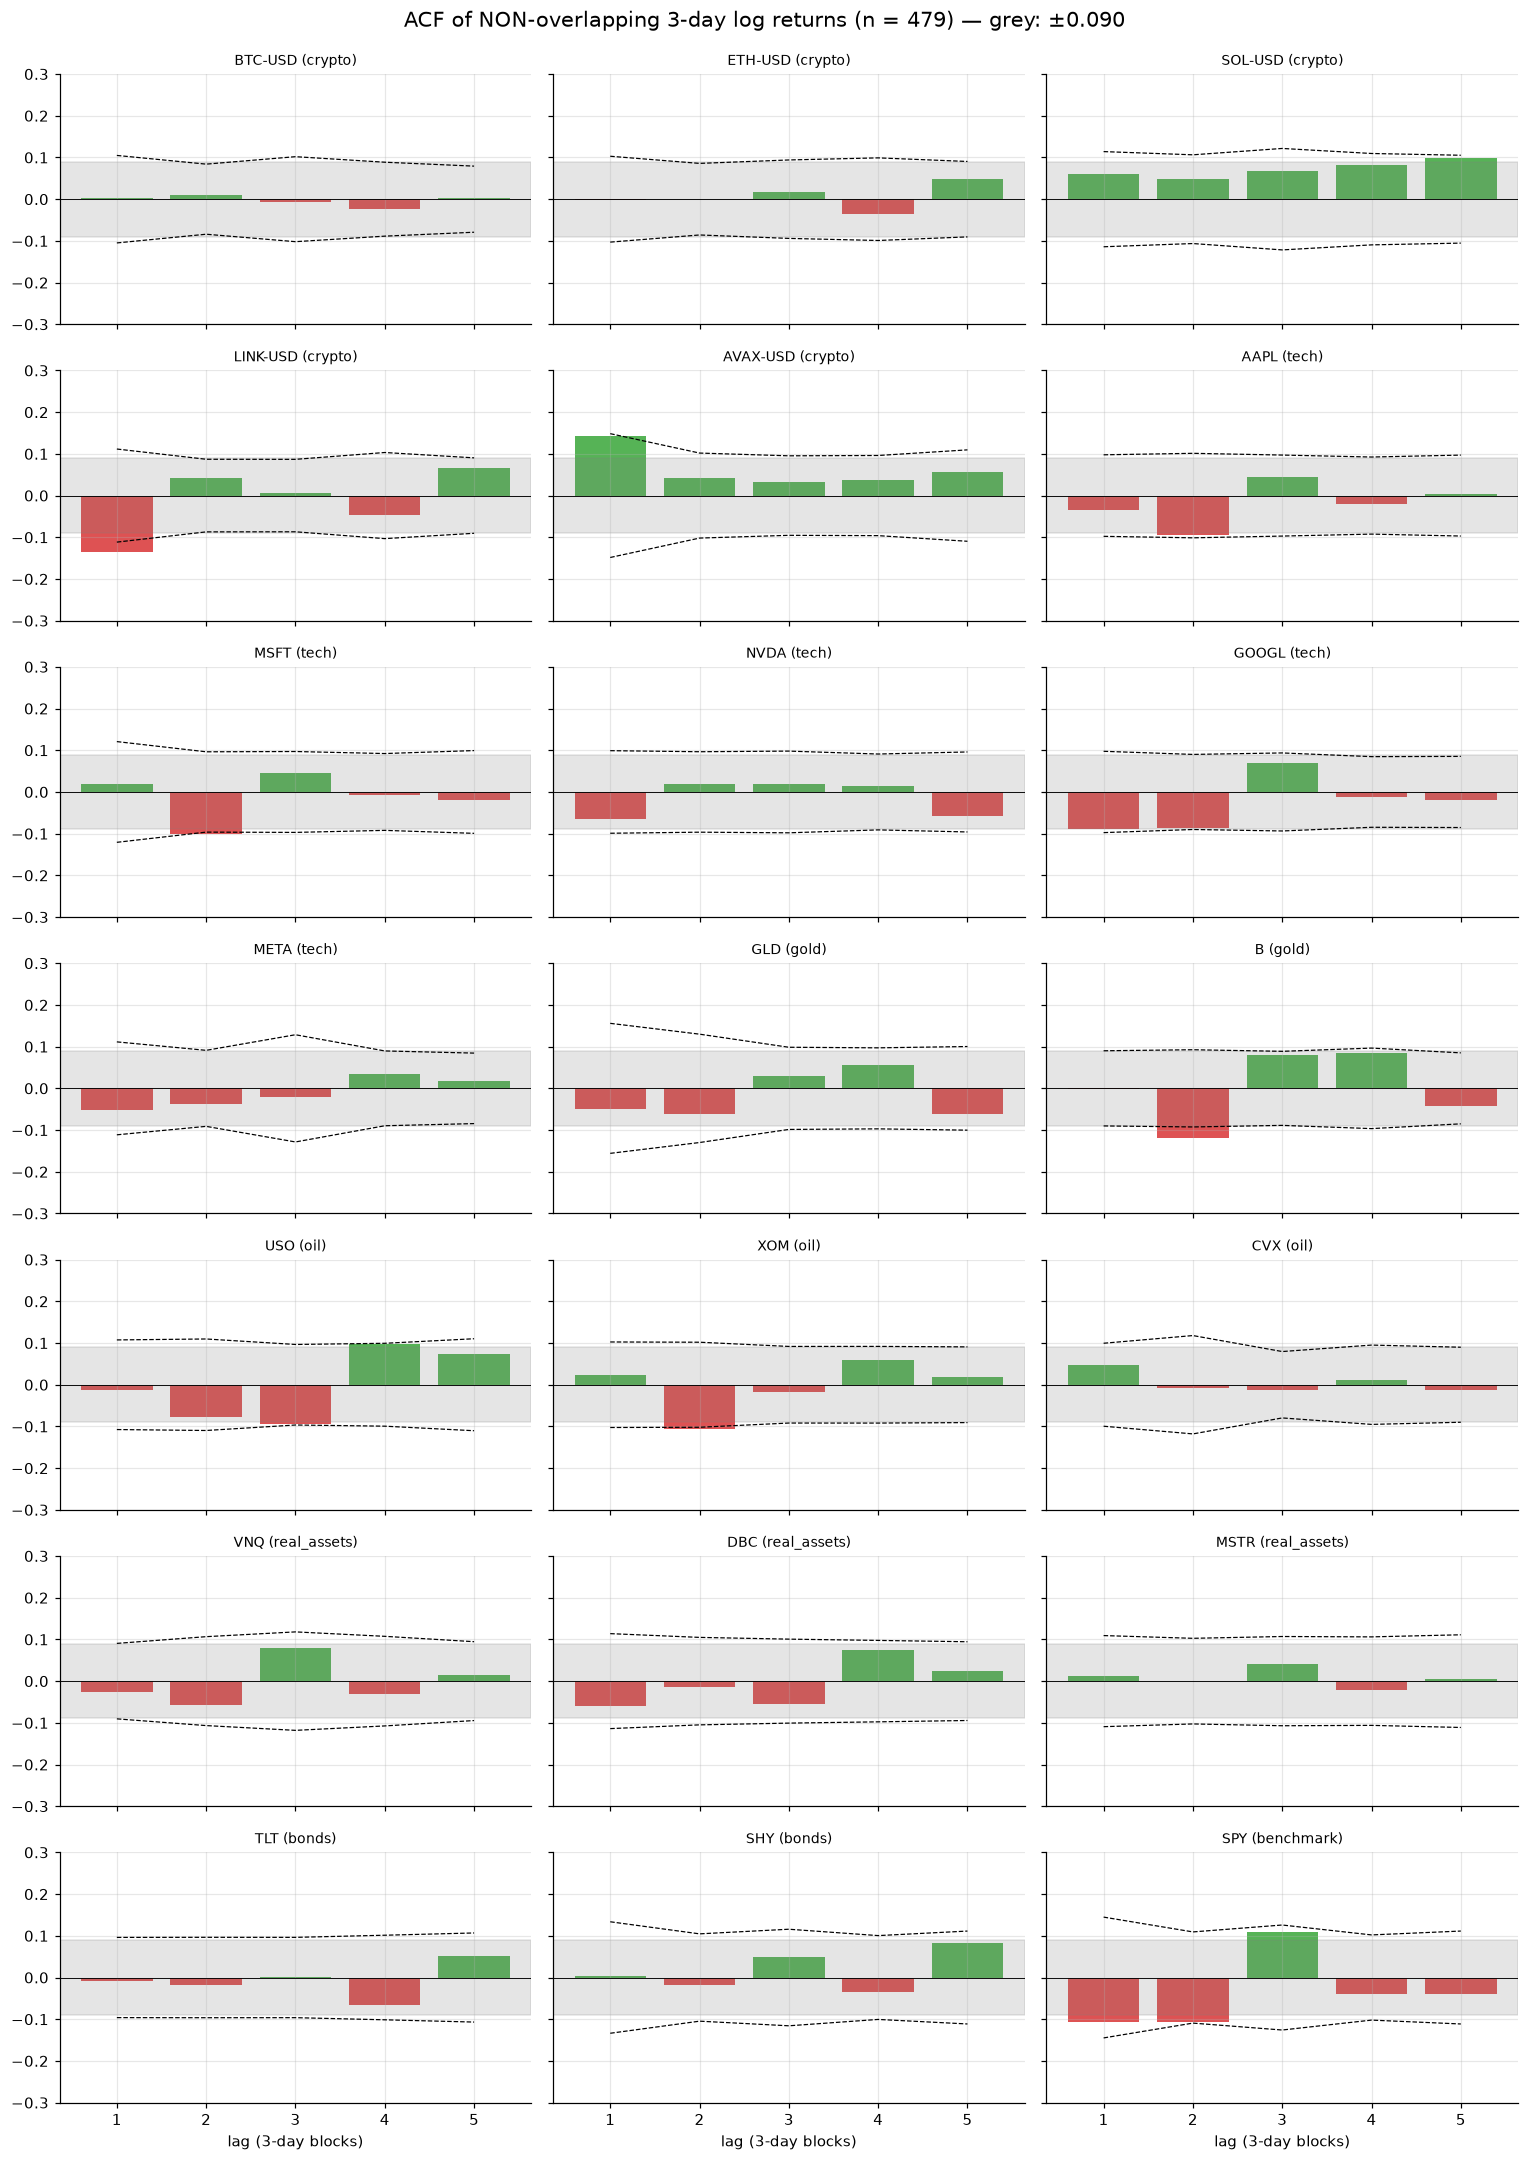

3-day significant bars: Bartlett 12, robust 4 out of 105 (≈5.2 expected by chance)


,rho1_3d
class,
benchmark,-0.1070
bonds,-0.0030
crypto,0.0140
gold,-0.0250
oil,0.0200
real_assets,-0.0250
tech,-0.0450


,class,rho1_3d,rho2_3d,robust_t_rho1_3d,n_sig_bartlett,n_sig_robust
BTC-USD,crypto,0.0030,0.0100,0.0620,0,0
ETH-USD,crypto,-0.0010,0.0010,-0.0260,0,0
SOL-USD,crypto,0.0590,0.0490,1.0210,1,0
LINK-USD,crypto,-0.1350,0.0420,-2.3760,1,1
AVAX-USD,crypto,0.1430,0.0430,1.8930,1,0
AAPL,tech,-0.0350,-0.0940,-0.6990,1,0
MSFT,tech,0.0190,-0.1000,0.3030,1,1
NVDA,tech,-0.0650,0.0200,-1.2950,0,0
GOOGL,tech,-0.0880,-0.0860,-1.7710,0,0
META,tech,-0.0530,-0.0380,-0.9330,0,0


In [12]:
r3 = eda.non_overlapping_sum(logr[ORDERED], h=3)
n3 = len(r3)
acf3 = eda.acf_table(r3, 5)
se3 = eda.robust_acf_se(r3, 5)
band3 = eda.acf_band(n3)

fig, axes = plt.subplots(7, 3, figsize=(14, 20), sharex=True, sharey=True)
lags3 = np.arange(1, 6)
for ax, t in zip(axes.flat, ORDERED):
    vals = acf3.loc[t].to_numpy()
    ax.bar(lags3, vals, color=np.where(vals > 0, "tab:green", "tab:red"), alpha=0.8)
    ax.axhspan(-band3, band3, color="grey", alpha=0.2)
    ax.plot(lags3, 1.96 * se3.loc[t], color="black", ls="--", lw=0.8)
    ax.plot(lags3, -1.96 * se3.loc[t], color="black", ls="--", lw=0.8)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{t} ({CLASS_OF[t]})", fontsize=9)
    ax.set_ylim(-0.3, 0.3)
for ax in axes[-1]:
    ax.set_xlabel("lag (3-day blocks)")
fig.suptitle(f"ACF of NON-overlapping 3-day log returns (n = {n3}) — grey: ±{band3:.3f}", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save_fig(fig, "g5_acf_3day_nonoverlap")
plt.show()

acf3_tbl = pd.DataFrame({
    "class": pd.Series(CLASS_OF), "rho1_3d": acf3[1], "rho2_3d": acf3[2],
    "robust_t_rho1_3d": acf3[1] / se3[1],
    "n_sig_bartlett": (acf3.abs() > band3).sum(axis=1), "n_sig_robust": (acf3.abs() > 1.96 * se3).sum(axis=1),
}).loc[ORDERED]
save_table(acf3_tbl, "g5_acf_3day_table")
print(f"3-day significant bars: Bartlett {acf3_tbl['n_sig_bartlett'].sum()}, robust {acf3_tbl['n_sig_robust'].sum()} "
      f"out of {len(ORDERED) * 5} (≈{0.05 * len(ORDERED) * 5:.1f} expected by chance)")
display(acf3_tbl.groupby("class")[["rho1_3d"]].mean().round(3))
acf3_tbl.round(3)

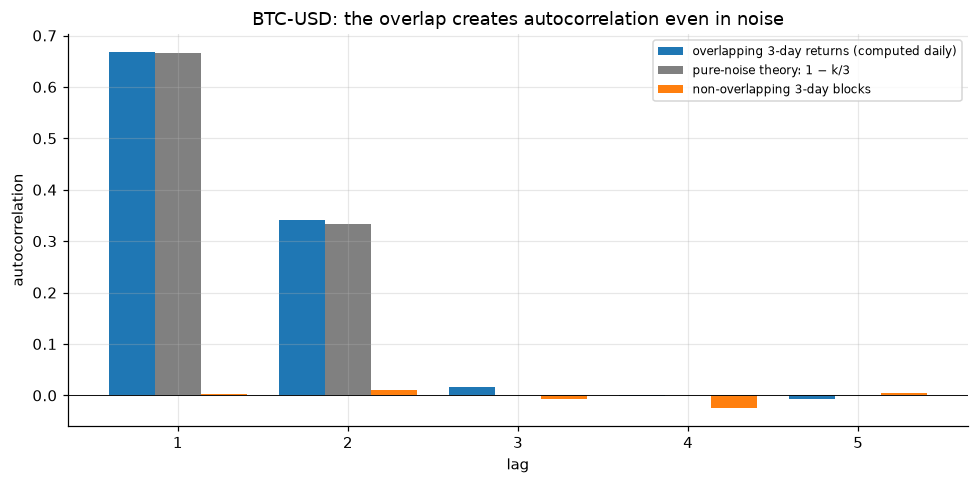

In [13]:
# The overlapping-returns trap, demonstrated on one asset
t = "BTC-USD"
overlap = logr[t].rolling(3).sum().dropna()
acf_over = eda.acf_table(overlap.to_frame(), 5).loc[t]
acf_non = acf3.loc[t]
theory = pd.Series([2 / 3, 1 / 3, 0, 0, 0], index=range(1, 6))

fig, ax = plt.subplots(figsize=(9, 4.5))
w = 0.27
ax.bar(np.arange(1, 6) - w, acf_over, width=w, label="overlapping 3-day returns (computed daily)")
ax.bar(np.arange(1, 6), theory, width=w, label="pure-noise theory: 1 − k/3", color="grey")
ax.bar(np.arange(1, 6) + w, acf_non, width=w, label="non-overlapping 3-day blocks")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("lag")
ax.set_ylabel("autocorrelation")
ax.set_title(f"{t}: the overlap creates autocorrelation even in noise")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "g5_overlap_trap")
plt.show()

**Reading.** The headline result: an asset's own last 1–10 daily returns do not predict its next return in any consistent way. The largest lag-1 autocorrelation is 0.058 (DBC), which explains at most 0.34% of tomorrow's variance. Across 210 tests, 14 bars cross the Bartlett band and 9 cross the robust band, about the 10.5 expected from pure luck. No class shows a clear momentum or reversal pattern. Bonds and SPY lean slightly negative (VR(3) 0.89–0.95, mild reversal), oil leans slightly positive (all three ρ1 > 0 but none significant), and crypto is mixed. Non-overlapping 3-day blocks give the same picture: 4 robust hits out of 105, against about 5 expected. SPY's apparent −0.11 three-day reversal passes Bartlett's band but fails the robust one, meaning it comes from volatile periods, not a steady effect. The overlap trap is reproduced exactly: overlapping 3-day BTC returns show 0.67 and 0.34, matching the pure-noise theory.

## Graph 6 — Autocorrelation of squared returns

$\hat\rho_k$ of $r_{i,t}^2$, lags 1–20. Volatility clustering shows up as **positive, slowly decaying** bars.

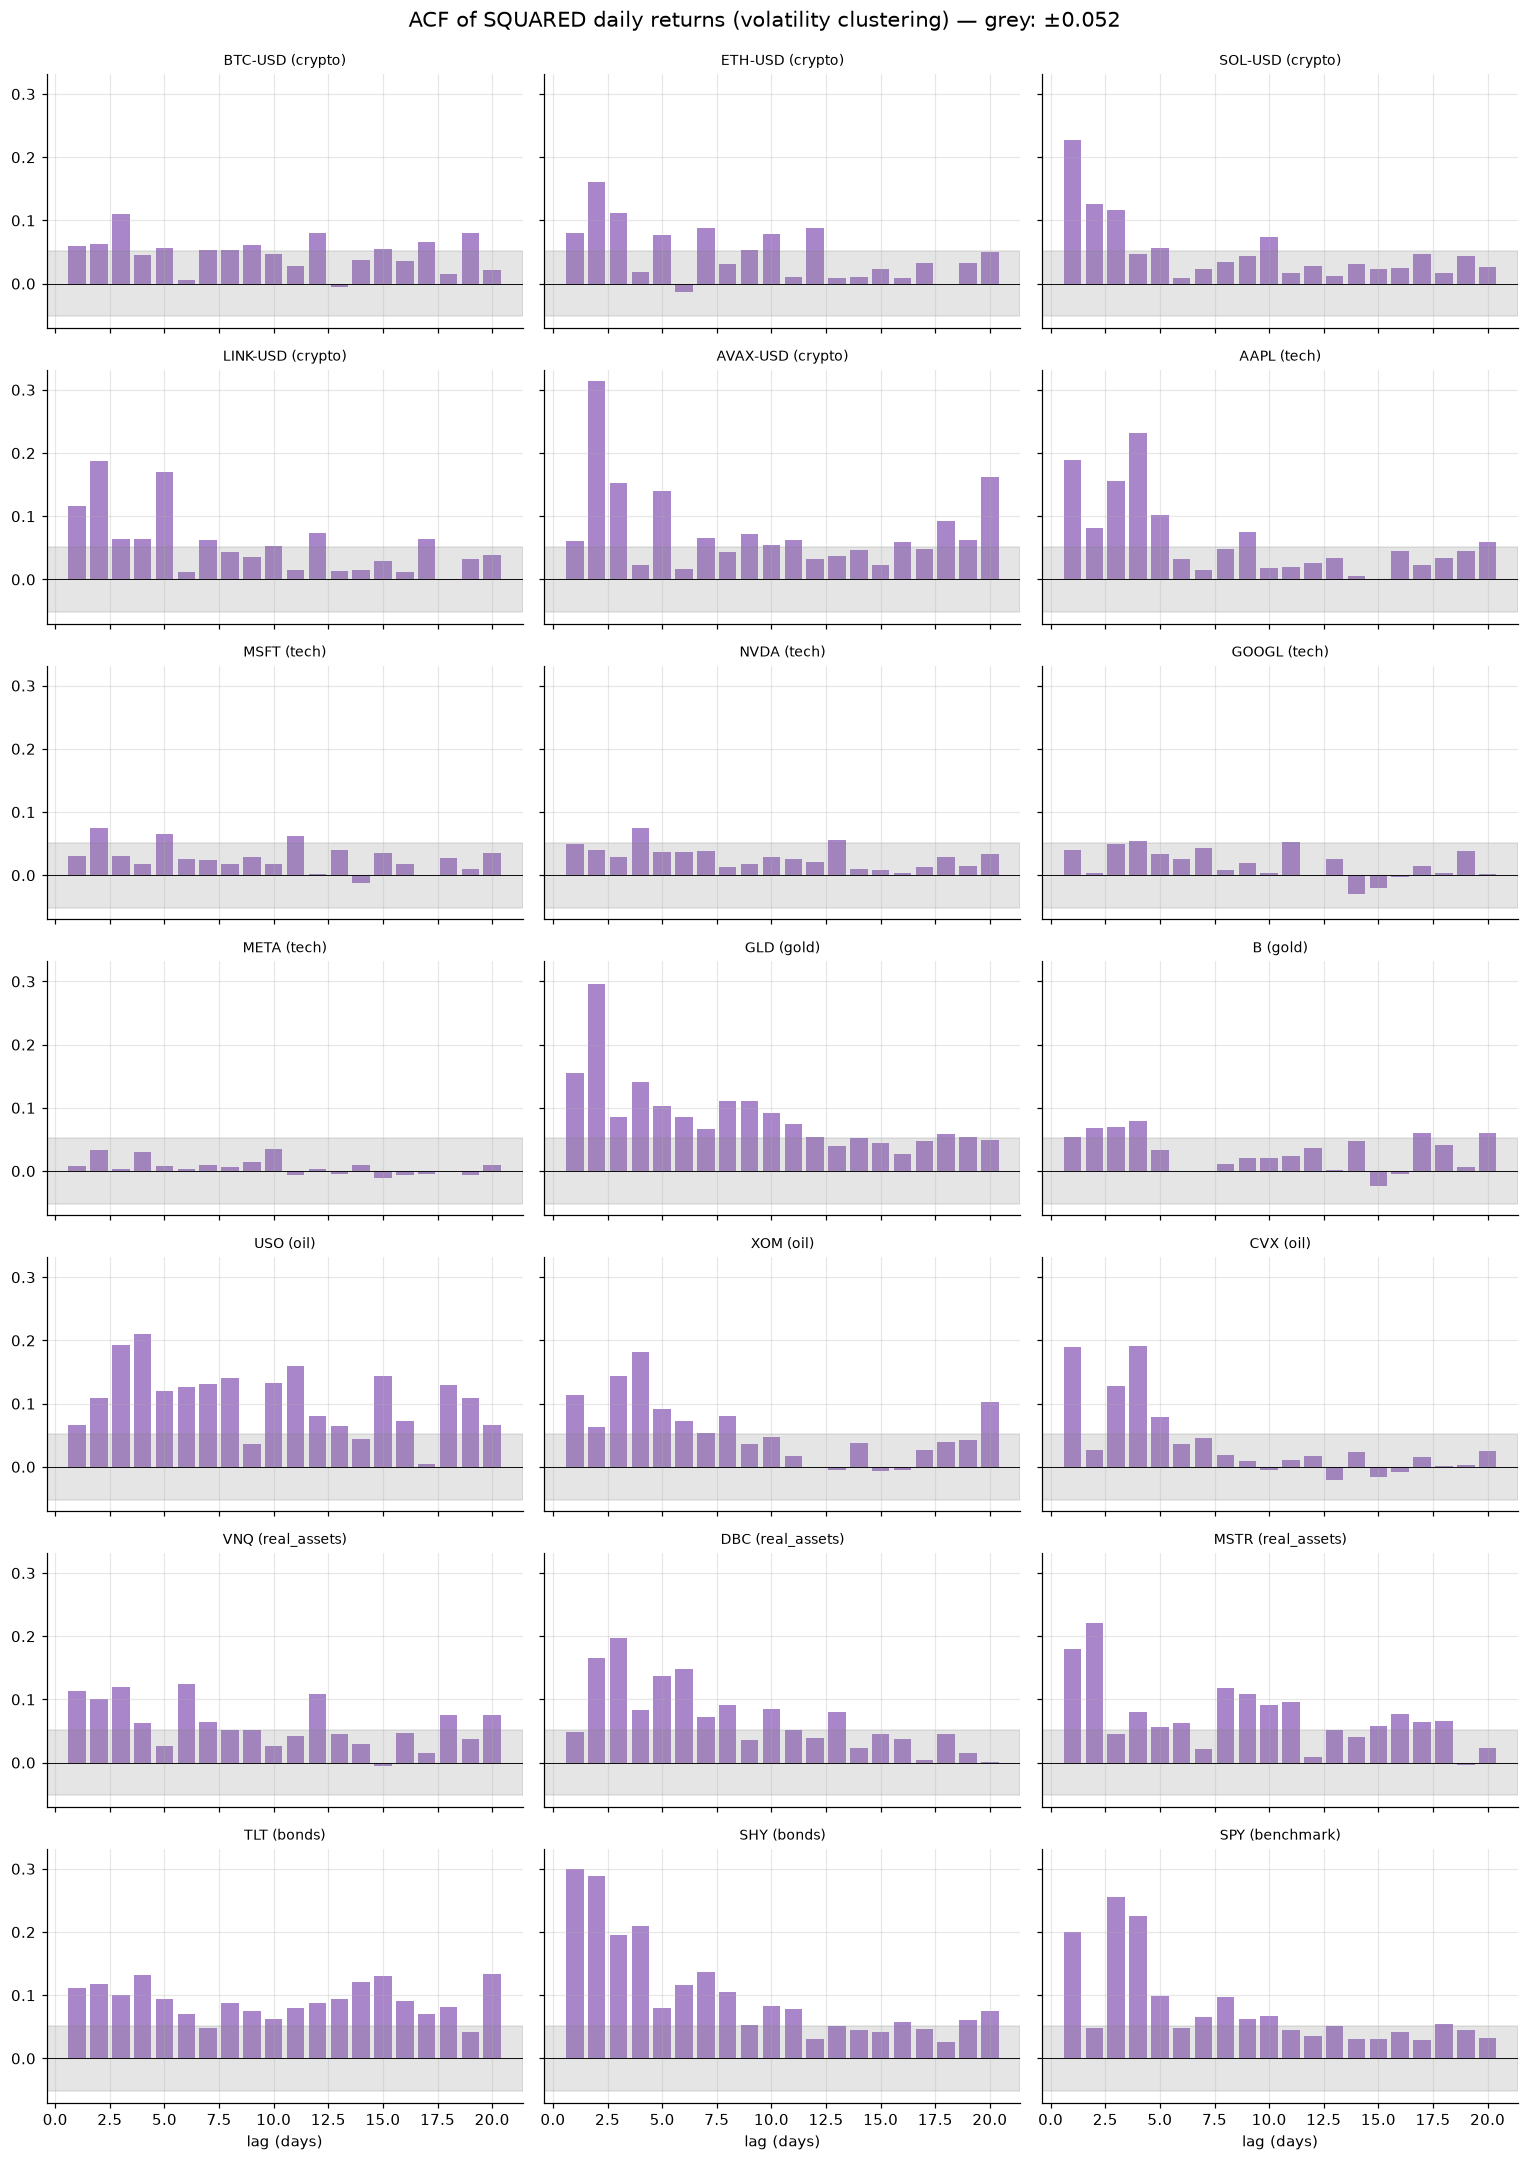

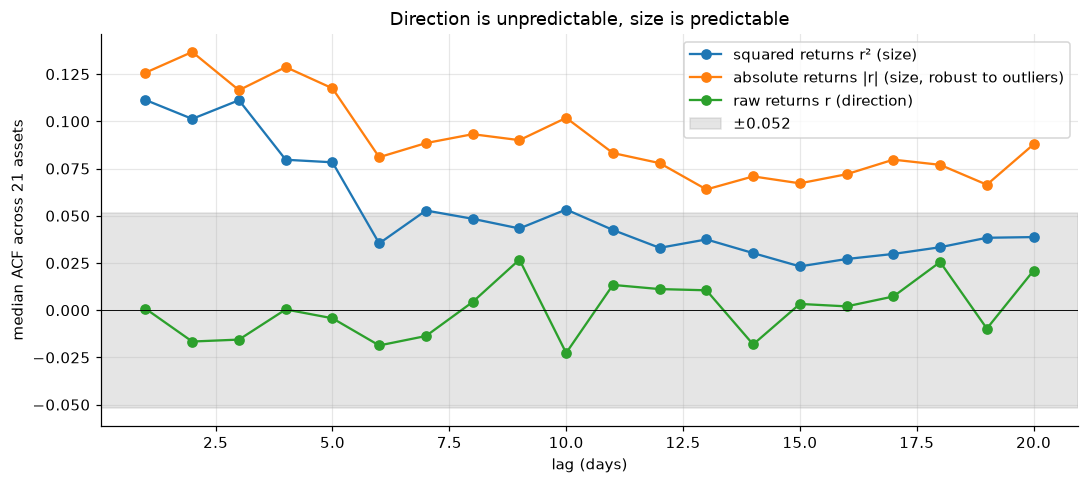

,class,acf_sq_lag1,acf_sq_lag5,acf_sq_lag10,acf_sq_lag20,n_lags_sig_of_20,acf_abs_lag1,acf_abs_lag20,n_abs_lags_sig_of_20
BTC-USD,crypto,0.0600,0.0570,0.0470,0.0220,11,0.1020,0.0640,17
ETH-USD,crypto,0.0800,0.0770,0.0780,0.0500,8,0.1260,0.0880,16
SOL-USD,crypto,0.2280,0.0560,0.0750,0.0260,5,0.2200,0.0750,18
LINK-USD,crypto,0.1160,0.1700,0.0530,0.0390,9,0.1530,0.1060,18
AVAX-USD,crypto,0.0610,0.1400,0.0550,0.1620,12,0.1380,0.1920,20
AAPL,tech,0.1880,0.1020,0.0180,0.0590,7,0.1920,0.1080,17
MSFT,tech,0.0310,0.0660,0.0180,0.0350,3,0.0890,0.0800,17
NVDA,tech,0.0490,0.0370,0.0280,0.0330,2,0.0690,0.0900,19
GOOGL,tech,0.0410,0.0340,0.0040,0.0030,2,0.0440,0.0480,8
META,tech,0.0070,0.0090,0.0350,0.0100,0,0.0370,0.0600,10


In [14]:
NL2 = 20
acf_sq = eda.acf_table(logr[ORDERED].pow(2), NL2)
acf_raw20 = eda.acf_table(logr[ORDERED], NL2)
acf_abs = eda.acf_table(logr[ORDERED].abs(), NL2)

fig, axes = plt.subplots(7, 3, figsize=(14, 20), sharex=True, sharey=True)
lags20 = np.arange(1, NL2 + 1)
for ax, t in zip(axes.flat, ORDERED):
    ax.bar(lags20, acf_sq.loc[t], color="tab:purple", alpha=0.8)
    ax.axhspan(-band, band, color="grey", alpha=0.2)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{t} ({CLASS_OF[t]})", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("lag (days)")
fig.suptitle(f"ACF of SQUARED daily returns (volatility clustering) — grey: ±{band:.3f}", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save_fig(fig, "g6_acf_squared")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(lags20, acf_sq.median(), marker="o", label="squared returns r² (size)")
ax.plot(lags20, acf_abs.median(), marker="o", label="absolute returns |r| (size, robust to outliers)")
ax.plot(lags20, acf_raw20.median(), marker="o", label="raw returns r (direction)")
ax.axhspan(-band, band, color="grey", alpha=0.2, label=f"±{band:.3f}")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("lag (days)")
ax.set_ylabel("median ACF across 21 assets")
ax.set_title("Direction is unpredictable, size is predictable")
ax.legend()
fig.tight_layout()
save_fig(fig, "g6_size_vs_direction")
plt.show()

sq_tbl = pd.DataFrame({
    "class": pd.Series(CLASS_OF),
    "acf_sq_lag1": acf_sq[1], "acf_sq_lag5": acf_sq[5], "acf_sq_lag10": acf_sq[10], "acf_sq_lag20": acf_sq[20],
    "n_lags_sig_of_20": (acf_sq > band).sum(axis=1),
    "acf_abs_lag1": acf_abs[1], "acf_abs_lag20": acf_abs[20],
    "n_abs_lags_sig_of_20": (acf_abs > band).sum(axis=1),
}).loc[ORDERED]
save_table(sq_tbl, "g6_acf_squared_table")
sq_tbl.round(3)

**Reading.** Size is predictable, direction is not. The median lag-1 autocorrelation is 0.126 for |r| and 0.111 for r², but only 0.001 for raw returns. Measured with |r|, 18 of 21 assets have at least 10 of 20 lags significant, still visible at lag 20 (strongest: TLT, SHY, AVAX, GLD). Measured with r², only 8 of 21 do, because squaring lets a few giant days dominate. META has zero significant r² lags but 10 significant |r| lags. Lesson: with fat tails, use |r| to detect clustering. Clustering is weakest in single stocks with earnings jumps (GOOGL, META, B, CVX).

## Hypothesis check (H1–H9)

Numbers behind each hypothesis in the Obsidian plan, §8.

In [15]:
equities = UNIVERSE["tech"] + ["XOM", "CVX", "B", "MSTR", BENCHMARK]
stress = {
    "2022": roll_corr.loc["2022"].mean(),
    "Apr-May 2025": roll_corr.loc["2025-04":"2025-05"].mean(),
    "median, full sample": roll_corr.median(),
}
evidence = {
    "H1 assets with >= 10/20 significant lags, r² | |r|": f"{(sq_tbl['n_lags_sig_of_20'] >= 10).sum()} | {(sq_tbl['n_abs_lags_sig_of_20'] >= 10).sum()} / {len(sq_tbl)}",
    "H9b median ACF lag1 |r|": f"{acf_abs[1].median():.3f}",
    "H2 assets with excess kurtosis > 0 and JB p < 0.05": f"{((moments['excess_kurt'] > 0) & (moments['jb_pvalue'] < 0.05)).sum()} / {len(moments)}",
    "H3 median kurtosis reduction after vol-scaling": f"{kurt_cmp['kurt_reduction'].median():.0%} (assets reduced: {(kurt_cmp['kurt_reduction'] > 0).sum()} / {len(kurt_cmp)})",
    "H4 equity skews": moments.loc[equities, "skew"].round(2).to_dict(),
    "H5 avg corr / N_eff (Pearson)": f"{avg_p:.2f} / {eda.effective_bets(n, avg_p):.1f}",
    "H6 rolling avg corr in stress vs median": {k: round(v, 2) for k, v in stress.items()},
    "H7 max |rho1|": f"{acf_tbl['rho1'].abs().max():.3f}",
    "H8 mean rho1 by class": by_class["mean_rho1"].round(3).to_dict(),
    "H9 median ACF lag1: squared vs raw": f"{acf_sq[1].median():.3f} vs {acf_raw20[1].median():.3f}",
}
for k, v in evidence.items():
    print(f"{k}:\n    {v}")

H1 assets with >= 10/20 significant lags, r² | |r|:
    8 | 18 / 21
H9b median ACF lag1 |r|:
    0.126
H2 assets with excess kurtosis > 0 and JB p < 0.05:
    21 / 21
H3 median kurtosis reduction after vol-scaling:
    22% (assets reduced: 14 / 21)
H4 equity skews:
    {'AAPL': 0.14, 'MSFT': 0.32, 'NVDA': 0.23, 'GOOGL': 0.02, 'META': -1.02, 'XOM': -0.25, 'CVX': -0.44, 'B': -0.14, 'MSTR': -0.04, 'SPY': 0.12}
H5 avg corr / N_eff (Pearson):
    0.21 / 3.9
H6 rolling avg corr in stress vs median:
    {'2022': np.float64(0.31), 'Apr-May 2025': np.float64(0.32), 'median, full sample': np.float64(0.19)}
H7 max |rho1|:
    0.058
H8 mean rho1 by class:
    {'benchmark': -0.028, 'bonds': -0.043, 'crypto': -0.008, 'gold': -0.003, 'oil': 0.026, 'real_assets': 0.009, 'tech': -0.006}
H9 median ACF lag1: squared vs raw:
    0.111 vs 0.001


**Reading.** H1 confirmed with |r| (18/21), mixed with r² (8/21). H2 confirmed (21/21). H3 partly confirmed: tails shrink for indices, ETFs and most crypto, but grow for jump-driven single stocks. H4 rejected as stated: equity skew is mixed and driven by a few days. H5 confirmed (N_eff ≈ 3.9, five blocks). H6 confirmed (0.31–0.32 in stress vs 0.19 median). H7 confirmed (max |ρ1| = 0.058). H8 rejected: no class-level short-term momentum or reversal. H9 confirmed.